# Pipeline Completo - Cáncer de estómago

## 1. Configuración y carga de datos

In [1]:
from pathlib import Path
import sys
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch
from libpysal.weights import Queen
from esda.moran import Moran

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyreadstat
import geopandas as gpd
import mapclassify
import cmdstanpy
from cmdstanpy import CmdStanModel

cmdstanpy.set_cmdstan_path(
    r"C:\Users\USER\anaconda3\envs\EEG_EDA_ML\Library\bin\cmdstan"
)

from IPython.display import display, HTML

RUTA_PROYECTO = Path(r"C:\Users\USER\Desktop\Tesis")
RUTA_DATOS = RUTA_PROYECTO / "Data"
RUTA_DIRECTORIOS = RUTA_PROYECTO / "Directorios"
RUTA_SRC = RUTA_PROYECTO / "src"
RUTA_POBLACION = RUTA_DATOS / "Poblacion"
RUTA_COVARIABLES = RUTA_DATOS / "Covariables"
RUTA_POBREZA = RUTA_COVARIABLES / "Pobreza_Monetaria"
RUTA_IPM = RUTA_COVARIABLES / "IPM"

if str(RUTA_SRC) not in sys.path:
    sys.path.append(str(RUTA_SRC))

from eda_toolkit import *

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

if "poblacion_mun" not in globals():
    poblacion_mun = pd.read_excel(
        RUTA_POBLACION / "poblacion_mun.xlsx"
    )
    print("Población municipal cargada.")
else:
    print("Población municipal ya disponible en memoria.")

if "poblacion_dpto_hombres" not in globals():
    poblacion_dpto_hombres = pd.read_excel(
        RUTA_POBLACION / "poblacion_dpto_hombres.xlsx"
    )
    print("Población departamental de hombres cargada.")
else:
    print("Población departamental de hombres ya disponible en memoria.")

if "poblacion_dpto_mujeres" not in globals():
    poblacion_dpto_mujeres = pd.read_excel(
        RUTA_POBLACION / "poblacion_dpto_mujeres.xlsx"
    )
    print("Población departamental de mujeres cargada.")
else:
    print("Población departamental de mujeres ya disponible en memoria.")

if "df_estomago" not in globals():
    df_estomago, meta_estomago = pyreadstat.read_sav(
        RUTA_DATOS / "ESTOMAGO2008_2024.sav"
    )
    print("Dataset de cáncer de estómago cargado correctamente.")
else:
    print("Dataset de cáncer de estómago ya disponible en memoria.")

if "ipm_2018" not in globals():
    ipm_2018 = gpd.read_file(
        RUTA_IPM / "MPM_FuenteCensal_2018.dbf"
    )
    print("IPM 2018 cargado correctamente.")
    print("Dimensiones:", ipm_2018.shape)
else:
    print("IPM 2018 ya disponible en memoria.")

Población municipal cargada.
Población departamental de hombres cargada.
Población departamental de mujeres cargada.
Dataset de cáncer de estómago cargado correctamente.
IPM 2018 cargado correctamente.
Dimensiones: (1122, 53)


## 2. Razón Estandarizada de Mortalidad (SMR)

La Razón Estandarizada de Mortalidad (SMR) permite comparar la mortalidad observada en una población con la mortalidad que se esperaría si dicha población experimentara las mismas tasas de mortalidad de una población de referencia.

Para el cáncer de estómago, el SMR se calcula mediante estandarización indirecta por edad y sexo. Primero se estiman las tasas específicas de mortalidad de la población de referencia y, posteriormente, estas tasas se aplican a la estructura poblacional de cada territorio para obtener el número esperado de defunciones.

El SMR se define como:


$$
SMR_i = \frac{O_i}{E_i}
$$

donde $O_i$ corresponde al número de defunciones observadas y $E_i$ al número de defunciones esperadas en el territorio $i$.

Un valor de $SMR_i = 1$ indica que la mortalidad observada coincide con la esperada, mientras que valores superiores a 1 representan un exceso de mortalidad y valores inferiores a 1 indican una mortalidad menor a la esperada.

### 2.1 SMR departamental anual

El análisis anual permite evaluar la evolución de la mortalidad relativa por cáncer de estómago en cada departamento entre 2010 y 2024. Para cada año se calcula la Razón Estandarizada de Mortalidad mediante estandarización indirecta por edad y sexo, utilizando las tasas nacionales específicas como población de referencia.

De esta forma, para cada departamento $i$ y año $t$:

$$
SMR_{it} = \frac{O_{it}}{E_{it}}
$$

donde $O_{it}$ representa las defunciones observadas y $E_{it}$ las defunciones esperadas según la estructura poblacional del departamento.

In [2]:
mapa_edad = {
    7: "menor_40",
    8: "menor_40",
    9: "menor_40",
    10: "menor_40",
    11: "menor_40",
    12: "menor_40",
    13: "menor_40",
    14: "menor_40",
    15: "menor_40",
    16: "40_44",
    17: "45_49",
    18: "50_54",
    19: "55_59",
    20: "60_64",
    21: "65_69",
    22: "70_74",
    23: "75_79",
    24: "80_84",
    25: "mayor_84",
    26: "mayor_84",
    27: "mayor_84",
    28: "mayor_84"
}

estomago_estratos = df_estomago.copy()

estomago_estratos["ANO"] = pd.to_numeric(
    estomago_estratos["ANO"],
    errors="coerce"
)

estomago_estratos["GRU_ED1"] = pd.to_numeric(
    estomago_estratos["GRU_ED1"],
    errors="coerce"
)

estomago_estratos["SEXO"] = pd.to_numeric(
    estomago_estratos["SEXO"],
    errors="coerce"
)

estomago_estratos["Grupo_edad"] = (
    estomago_estratos["GRU_ED1"].map(mapa_edad)
)

estomago_estratos["Sexo"] = estomago_estratos["SEXO"].map({
    1: "Hombres",
    2: "Mujeres"
})

estomago_estratos = estomago_estratos[
    estomago_estratos["ANO"].between(2010, 2024)
    & estomago_estratos["Grupo_edad"].notna()
    & estomago_estratos["Sexo"].notna()
].copy()

print("Registros utilizados:", len(estomago_estratos))

Registros utilizados: 76121


In [3]:
estomago_smr = df_estomago.copy()

estomago_smr["ANO"] = pd.to_numeric(
    estomago_smr["ANO"],
    errors="coerce"
)

estomago_smr["COD_DPTO"] = pd.to_numeric(
    estomago_smr["COD_DPTO"],
    errors="coerce"
)

estomago_smr = estomago_smr[
    estomago_smr["ANO"].between(2010, 2024)
    & estomago_smr["COD_DPTO"].notna()
].copy()

estomago_smr["dpto_ccdgo"] = (
    estomago_smr["COD_DPTO"]
    .astype(int)
    .astype(str)
    .str.zfill(2)
)

observadas_departamento_anual = (
    estomago_smr
    .groupby(["dpto_ccdgo", "ANO"], as_index=False)
    .size()
    .rename(columns={"size": "Observadas"})
)

In [4]:
poblacion_dpto = pd.read_excel(
    RUTA_POBLACION / "poblacion_dpto.xlsx"
)

In [5]:
casos_nacionales_anuales = (
    estomago_smr
    .groupby("ANO", as_index=False)
    .size()
    .rename(columns={"size": "Observadas_nacionales"})
)

poblacion_nacional_anual = (
    poblacion_dpto[
        poblacion_dpto["ANO"].between(2010, 2024)
    ]
    .groupby("ANO", as_index=False)
    .agg(Poblacion_nacional=("Total", "sum"))
)

riesgo_nacional_anual = casos_nacionales_anuales.merge(
    poblacion_nacional_anual,
    on="ANO",
    how="left",
    validate="one_to_one"
)

riesgo_nacional_anual["Riesgo_nacional"] = (
    riesgo_nacional_anual["Observadas_nacionales"]
    / riesgo_nacional_anual["Poblacion_nacional"]
)

In [6]:
esperadas_departamento_anual = (
    poblacion_dpto[
        poblacion_dpto["ANO"].between(2010, 2024)
    ]
    .merge(
        riesgo_nacional_anual[
            ["ANO", "Riesgo_nacional"]
        ],
        on="ANO",
        how="left",
        validate="many_to_one"
    )
)

esperadas_departamento_anual["Esperadas"] = (
    esperadas_departamento_anual["Total"]
    * esperadas_departamento_anual["Riesgo_nacional"]
)

esperadas_departamento_anual["dpto_ccdgo"] = (
    pd.to_numeric(
        esperadas_departamento_anual["dpto_ccdgo"],
        errors="coerce"
    )
    .astype("Int64")
    .astype(str)
    .str.zfill(2)
)

In [7]:
smr_departamento_anual = esperadas_departamento_anual[
    ["dpto_ccdgo", "DPNOM", "ANO", "Esperadas"]
].merge(
    observadas_departamento_anual,
    on=["dpto_ccdgo", "ANO"],
    how="left",
    validate="one_to_one"
)

smr_departamento_anual["Observadas"] = (
    smr_departamento_anual["Observadas"]
    .fillna(0)
    .astype(int)
)

smr_departamento_anual["SMR"] = (
    smr_departamento_anual["Observadas"]
    / smr_departamento_anual["Esperadas"]
)

smr_departamento_anual = (
    smr_departamento_anual[
        [
            "ANO",
            "dpto_ccdgo",
            "DPNOM",
            "Observadas",
            "Esperadas",
            "SMR"
        ]
    ]
    .sort_values(["ANO", "dpto_ccdgo"])
    .reset_index(drop=True)
)

In [8]:
tabla_smr_anual = (
    smr_departamento_anual[
        smr_departamento_anual["ANO"] == 2010
    ]
    .copy()
    .sort_values("SMR", ascending=False)
)

tabla_smr_anual["ANO"] = tabla_smr_anual["ANO"].astype(int)
tabla_smr_anual["Esperadas"] = tabla_smr_anual["Esperadas"].round(2)
tabla_smr_anual["SMR"] = tabla_smr_anual["SMR"].round(2)

styled_smr_anual = tabla_smr_anual.style.hide(axis="index").set_table_styles([
    {
        "selector": "",
        "props": [
            ("margin-left", "auto"),
            ("margin-right", "auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
])

styled_smr_anual = styled_smr_anual.set_properties(
    subset=["DPNOM"],
    **{"text-align": "left"}
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_smr_anual.to_html()
        + "</div>"
    )
)

ANO,dpto_ccdgo,DPNOM,Observadas,Esperadas,SMR
2010,63,Quindio,129,53.110000,2.430000
2010,17,Caldas,160,101.050000,1.580000
2010,66,Risaralda,142,92.700000,1.530000
2010,19,Cauca,201,138.900000,1.450000
2010,15,Boyacá,172,119.620000,1.440000
2010,52,Nariño,231,161.120000,1.430000
2010,41,Huila,142,102.800000,1.380000
2010,54,Norte de Santander,185,140.020000,1.320000
2010,73,Tolima,177,134.770000,1.310000
2010,11,"Bogotá, D.C.",868,728.580000,1.190000


### 2.2 SMR departamental quinquenal

Además del análisis anual, se calcula el SMR para tres quinquenios: 2010–2014, 2015–2019 y 2020–2024. Esta agrupación permite reducir la variabilidad anual y observar con mayor claridad la persistencia espacial de la mortalidad por cáncer de estómago.

Para cada departamento $i$ y quinquenio $q$, se agregan las defunciones observadas y esperadas correspondientes a los años que conforman el periodo:

$$
O_{iq} = \sum_{t \in q} O_{it}
$$

$$
E_{iq} = \sum_{t \in q} E_{it}
$$

El SMR quinquenal se obtiene mediante:

$$
SMR_{iq} = \frac{O_{iq}}{E_{iq}}
$$

De esta manera, un SMR superior a 1 indica que durante el quinquenio el número de defunciones observadas fue mayor al esperado según el riesgo nacional.

In [9]:
smr_departamento_quinquenal = smr_departamento_anual.copy()

smr_departamento_quinquenal["Quinquenio"] = pd.cut(
    smr_departamento_quinquenal["ANO"],
    bins=[2009, 2014, 2019, 2024],
    labels=["2010-2014", "2015-2019", "2020-2024"]
)

In [10]:
smr_departamento_quinquenal = (
    smr_departamento_quinquenal
    .groupby(
        ["dpto_ccdgo", "Quinquenio"],
        observed=True,
        as_index=False
    )
    .agg(
        Observadas=("Observadas", "sum"),
        Esperadas=("Esperadas", "sum")
    )
)

nombres_departamentos = (
    smr_departamento_anual[
        ["dpto_ccdgo", "DPNOM"]
    ]
    .drop_duplicates("dpto_ccdgo", keep="last")
)

smr_departamento_quinquenal = smr_departamento_quinquenal.merge(
    nombres_departamentos,
    on="dpto_ccdgo",
    how="left",
    validate="many_to_one"
)

smr_departamento_quinquenal["SMR"] = (
    smr_departamento_quinquenal["Observadas"]
    / smr_departamento_quinquenal["Esperadas"]
)

smr_departamento_quinquenal = (
    smr_departamento_quinquenal[
        [
            "Quinquenio",
            "dpto_ccdgo",
            "DPNOM",
            "Observadas",
            "Esperadas",
            "SMR"
        ]
    ]
    .sort_values(["Quinquenio", "SMR"], ascending=[True, False])
    .reset_index(drop=True)
)

In [11]:
tabla_smr_quinquenal = smr_departamento_quinquenal.copy()

tabla_smr_quinquenal["Esperadas"] = tabla_smr_quinquenal["Esperadas"].round(2)
tabla_smr_quinquenal["SMR"] = tabla_smr_quinquenal["SMR"].round(2)

styled_smr_quinquenal = tabla_smr_quinquenal.style.hide(axis="index").set_table_styles([
    {
        "selector": "",
        "props": [
            ("margin-left", "auto"),
            ("margin-right", "auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
])

styled_smr_quinquenal = styled_smr_quinquenal.set_properties(
    subset=["DPNOM"],
    **{"text-align": "left"}
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_smr_quinquenal.to_html()
        + "</div>"
    )
)

Quinquenio,dpto_ccdgo,DPNOM,Observadas,Esperadas,SMR
2010-2014,63,Quindío,540,272.280000,1.980000
2010-2014,66,Risaralda,787,476.680000,1.650000
2010-2014,41,Huila,789,536.370000,1.470000
2010-2014,17,Caldas,737,514.140000,1.430000
2010-2014,52,Nariño,1166,829.550000,1.410000
2010-2014,73,Tolima,939,688.160000,1.360000
2010-2014,15,Boyacá,824,615.120000,1.340000
2010-2014,54,Norte de Santander,962,723.410000,1.330000
2010-2014,11,"Bogotá, D.C.",4986,3757.950000,1.330000
2010-2014,19,Cauca,908,721.880000,1.260000


### 2.3 SMR municipal anual

El SMR municipal anual permite comparar las defunciones observadas por cáncer de estómago en cada municipio con las defunciones esperadas según el riesgo nacional de mortalidad correspondiente a cada año.

Para cada municipio $j$ y año $t$, el número esperado de defunciones se calcula mediante:

<!-- $$ -->
E_{jt} = P_{jt}r_t
$$

donde $P_{jt}$ corresponde a la población del municipio y $r_t$ al riesgo nacional de mortalidad por cáncer de estómago en el año $t$.

El SMR municipal anual se obtiene mediante:

$$
SMR_{jt} = \frac{O_{jt}}{E_{jt}}
$$


#### 2.3.1 Defunciones observadas por municipio y año

In [12]:
estomago_smr["COD_MUNIC"] = pd.to_numeric(
    estomago_smr["COD_MUNIC"],
    errors="coerce"
)

estomago_smr["mpio_cdpmp"] = (
    estomago_smr["COD_DPTO"]
    .astype(int)
    .astype(str)
    .str.zfill(2)
    +
    estomago_smr["COD_MUNIC"]
    .astype("Int64")
    .astype(str)
    .str.zfill(3)
)

observadas_municipio_anual = (
    estomago_smr[
        estomago_smr["COD_MUNIC"].notna()
    ]
    .groupby(["mpio_cdpmp", "ANO"], as_index=False)
    .size()
    .rename(columns={"size": "Observadas"})
)

#### 2.3.2 Defunciones esperadas

In [13]:
esperadas_municipio_anual = (
    poblacion_mun[
        poblacion_mun["ANO"].between(2010, 2024)
    ]
    .merge(
        riesgo_nacional_anual[
            ["ANO", "Riesgo_nacional"]
        ],
        on="ANO",
        how="left",
        validate="many_to_one"
    )
)

esperadas_municipio_anual["Esperadas"] = (
    esperadas_municipio_anual["Total"]
    * esperadas_municipio_anual["Riesgo_nacional"]
)

esperadas_municipio_anual["mpio_cdpmp"] = (
    pd.to_numeric(
        esperadas_municipio_anual["mpio_cdpmp"],
        errors="coerce"
    )
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
)

#### 2.3.3 SMR municipal anual

In [14]:
smr_municipio_anual = esperadas_municipio_anual[
    ["dpto_ccdgo", "DPNOM", "mpio_cdpmp", "DPMP", "ANO", "Esperadas"]
].merge(
    observadas_municipio_anual,
    on=["mpio_cdpmp", "ANO"],
    how="left",
    validate="one_to_one"
)

smr_municipio_anual["Observadas"] = (
    smr_municipio_anual["Observadas"]
    .fillna(0)
    .astype(int)
)

smr_municipio_anual["SMR"] = (
    smr_municipio_anual["Observadas"]
    / smr_municipio_anual["Esperadas"]
)

smr_municipio_anual = (
    smr_municipio_anual[
        [
            "ANO",
            "dpto_ccdgo",
            "DPNOM",
            "mpio_cdpmp",
            "DPMP",
            "Observadas",
            "Esperadas",
            "SMR"
        ]
    ]
    .sort_values(["ANO", "mpio_cdpmp"])
    .reset_index(drop=True)
)

In [15]:
tabla_smr_municipal_anual = (
    smr_municipio_anual
    .groupby("ANO")
    .agg(
        Municipios=("mpio_cdpmp", "nunique"),
        Observadas=("Observadas", "sum"),
        Esperadas=("Esperadas", "sum"),
        SMR_min=("SMR", "min"),
        SMR_max=("SMR", "max")
    )
    .reset_index()
)

tabla_smr_municipal_anual["ANO"] = tabla_smr_municipal_anual["ANO"].astype(int)

styled = (
    tabla_smr_municipal_anual.style
    .hide(axis="index")
    .format({
        "ANO": "{:.0f}",
        "Municipios": "{:,.0f}",
        "Observadas": "{:,.0f}",
        "Esperadas": "{:,.2f}",
        "SMR_min": "{:.2f}",
        "SMR_max": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

ANO,Municipios,Observadas,Esperadas,SMR_min,SMR_max
2010,"1,122","4,526","4,526.00",0.00,15.62
2011,"1,122","4,509","4,509.00",0.00,8.08
2012,"1,122","4,650","4,650.00",0.00,8.52
2013,"1,122","4,818","4,818.00",0.00,9.30
2014,"1,122","5,030","5,030.00",0.00,9.40
2015,"1,122","5,111","5,111.00",0.00,10.53
2016,"1,122","5,086","5,086.00",0.00,6.80
2017,"1,122","5,201","5,201.00",0.00,6.52
2018,"1,123","5,339","5,339.00",0.00,11.86
2019,"1,123","5,434","5,434.00",0.00,7.51


### 2.4 SMR municipal quinquenal

Para reducir la variabilidad anual y analizar patrones temporales más estables a escala municipal, las defunciones observadas y esperadas se agregan en los quinquenios 2010–2014, 2015–2019 y 2020–2024.

Para cada municipio $j$ y quinquenio $q$, el SMR se calcula mediante:

$$
SMR_{jq} = \frac{\sum_{t \in q} O_{jt}}{\sum_{t \in q} E_{jt}}
$$

De esta manera, el SMR quinquenal compara las defunciones observadas acumuladas en cada municipio con las defunciones esperadas acumuladas durante el mismo periodo.

In [16]:
smr_municipio_quinquenal = smr_municipio_anual.copy()

smr_municipio_quinquenal["Quinquenio"] = pd.cut(
    smr_municipio_quinquenal["ANO"],
    bins=[2009, 2014, 2019, 2024],
    labels=["2010-2014", "2015-2019", "2020-2024"]
)

smr_municipio_quinquenal = (
    smr_municipio_quinquenal
    .groupby(
        ["mpio_cdpmp", "Quinquenio"],
        observed=True,
        as_index=False
    )
    .agg(
        Observadas=("Observadas", "sum"),
        Esperadas=("Esperadas", "sum")
    )
)

In [17]:
nombres_municipios = (
    smr_municipio_anual[
        ["mpio_cdpmp", "dpto_ccdgo", "DPNOM", "DPMP"]
    ]
    .drop_duplicates("mpio_cdpmp", keep="last")
)

smr_municipio_quinquenal = smr_municipio_quinquenal.merge(
    nombres_municipios,
    on="mpio_cdpmp",
    how="left",
    validate="many_to_one"
)

smr_municipio_quinquenal["SMR"] = (
    smr_municipio_quinquenal["Observadas"]
    / smr_municipio_quinquenal["Esperadas"]
)

smr_municipio_quinquenal = (
    smr_municipio_quinquenal[
        [
            "Quinquenio",
            "dpto_ccdgo",
            "DPNOM",
            "mpio_cdpmp",
            "DPMP",
            "Observadas",
            "Esperadas",
            "SMR"
        ]
    ]
    .sort_values(["Quinquenio", "mpio_cdpmp"])
    .reset_index(drop=True)
)

In [18]:
tabla_smr_municipal_quinquenal = (
    smr_municipio_quinquenal
    .groupby(
        "Quinquenio",
        observed=True
    )
    .agg(
        Municipios=("mpio_cdpmp", "nunique"),
        Observadas=("Observadas", "sum"),
        Esperadas=("Esperadas", "sum"),
        SMR_min=("SMR", "min"),
        SMR_max=("SMR", "max")
    )
    .reset_index()
)

styled = (
    tabla_smr_municipal_quinquenal.style
    .hide(axis="index")
    .format({
        "Municipios": "{:,.0f}",
        "Observadas": "{:,.0f}",
        "Esperadas": "{:,.2f}",
        "SMR_min": "{:.2f}",
        "SMR_max": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Quinquenio"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Quinquenio,Municipios,Observadas,Esperadas,SMR_min,SMR_max
2010-2014,"1,122","23,533","23,533.00",0.00,3.83
2015-2019,"1,123","26,171","26,171.00",0.00,3.70
2020-2024,"1,123","26,418","26,418.00",0.00,3.84


## 3. Distribución espacial del SMR departamental

#### 3.1 Preparación de la información geográfica

Para representar espacialmente los resultados, se integra la información del SMR con la división político-administrativa de Colombia. La correspondencia entre ambas fuentes se realiza mediante el código departamental.

In [19]:
RUTA_GEOGRAFIA = RUTA_DATOS / "Geografia" / "shapefile"

gdf_colombia = gpd.read_file(
    RUTA_GEOGRAFIA / "MPM_FuenteCensal_2018.shp"
)

gdf_colombia = gdf_colombia.to_crs(epsg=4326)

In [20]:
gdf_departamentos = (
    gdf_colombia[
        ["DPTO_CCDGO", "DPTO_CNMBR", "geometry"]
    ]
    .dissolve(
        by="DPTO_CCDGO",
        as_index=False
    )
)

gdf_departamentos["DPTO_CCDGO"] = (
    gdf_departamentos["DPTO_CCDGO"]
    .astype(str)
    .str.zfill(2)
)

tabla_departamentos = gdf_departamentos[
    ["DPTO_CCDGO", "DPTO_CNMBR"]
].head()

styled = (
    tabla_departamentos.style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["DPTO_CNMBR"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

DPTO_CCDGO,DPTO_CNMBR
05,ANTIOQUIA
08,ATLÁNTICO
11,"BOGOTÁ, D.C."
13,BOLÍVAR
15,BOYACÁ


In [21]:
gdf_smr_quinquenal = gdf_departamentos.merge(
    smr_departamento_quinquenal,
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left",
    validate="one_to_many"
)

gdf_smr_quinquenal[
    [
        "DPTO_CCDGO",
        "DPTO_CNMBR",
        "Quinquenio",
        "Observadas",
        "Esperadas",
        "SMR"
    ]
].head(10)

,DPTO_CCDGO,DPTO_CNMBR,Quinquenio,Observadas,Esperadas,SMR
0,05,ANTIOQUIA,2010-2014,3125,"3,104.50",1.01
1,05,ANTIOQUIA,2015-2019,3663,"3,470.03",1.06
2,05,ANTIOQUIA,2020-2024,3670,"3,467.55",1.06
3,08,ATLÁNTICO,2010-2014,490,"1,210.93",0.40
4,08,ATLÁNTICO,2015-2019,729,"1,366.74",0.53
5,08,ATLÁNTICO,2020-2024,707,"1,418.87",0.50
6,11,"BOGOTÁ, D.C.",2010-2014,4986,"3,757.95",1.33
7,11,"BOGOTÁ, D.C.",2015-2019,5732,"4,048.94",1.42
8,11,"BOGOTÁ, D.C.",2020-2024,5752,"4,013.47",1.43
9,13,BOLÍVAR,2010-2014,345,"1,016.60",0.34


In [22]:
gdf_smr_quinquenal.groupby(
    "Quinquenio",
    observed=True
)["SMR"].agg(["count", "min", "max"])

,count,min,max
Quinquenio,,,
2010-2014,33,0.09,1.98
2015-2019,33,0.03,1.74
2020-2024,33,0.00,1.90


#### 3.2 Clasificación del SMR

Para facilitar la interpretación espacial, los valores del SMR se agrupan en categorías que permiten diferenciar departamentos sin casos, departamentos con mortalidad inferior a la esperada y departamentos con exceso de mortalidad.

In [23]:
def clasificar_smr(row):
    if row["Observadas"] == 0:
        return "Sin casos"
    if row["SMR"] < 0.7:
        return "SMR < 0.7"
    if row["SMR"] < 0.9:
        return "0.7 ≤ SMR < 0.9"
    if row["SMR"] < 1.1:
        return "0.9 ≤ SMR < 1.1"
    if row["SMR"] < 1.4:
        return "1.1 ≤ SMR < 1.4"
    return "SMR ≥ 1.4"

gdf_smr_quinquenal["Categoria_SMR"] = gdf_smr_quinquenal.apply(
    clasificar_smr,
    axis=1
)

In [24]:
colores_smr = {
    "Sin casos": "#f0f0f0",
    "SMR < 0.7": "#fee6ce",
    "0.7 ≤ SMR < 0.9": "#fdd0a2",
    "0.9 ≤ SMR < 1.1": "#fdae6b",
    "1.1 ≤ SMR < 1.4": "#f16913",
    "SMR ≥ 1.4": "#8c2d04"
}

orden_leyenda = [
    "Sin casos",
    "SMR < 0.7",
    "0.7 ≤ SMR < 0.9",
    "0.9 ≤ SMR < 1.1",
    "1.1 ≤ SMR < 1.4",
    "SMR ≥ 1.4"
]

#### 3.3 Mapas anuales del SMR

Los mapas anuales permiten observar la evolución espacial del SMR departamental entre 2010 y 2024, identificando cambios interanuales en la distribución geográfica de la mortalidad por cáncer de estómago.

Para mantener la comparabilidad temporal, se utiliza la misma clasificación del SMR en todos los años analizados.

In [25]:
gdf_smr_anual = gdf_departamentos.merge(
    smr_departamento_anual,
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left",
    validate="one_to_many"
)

gdf_smr_anual["Categoria_SMR"] = gdf_smr_anual.apply(
    clasificar_smr,
    axis=1
)

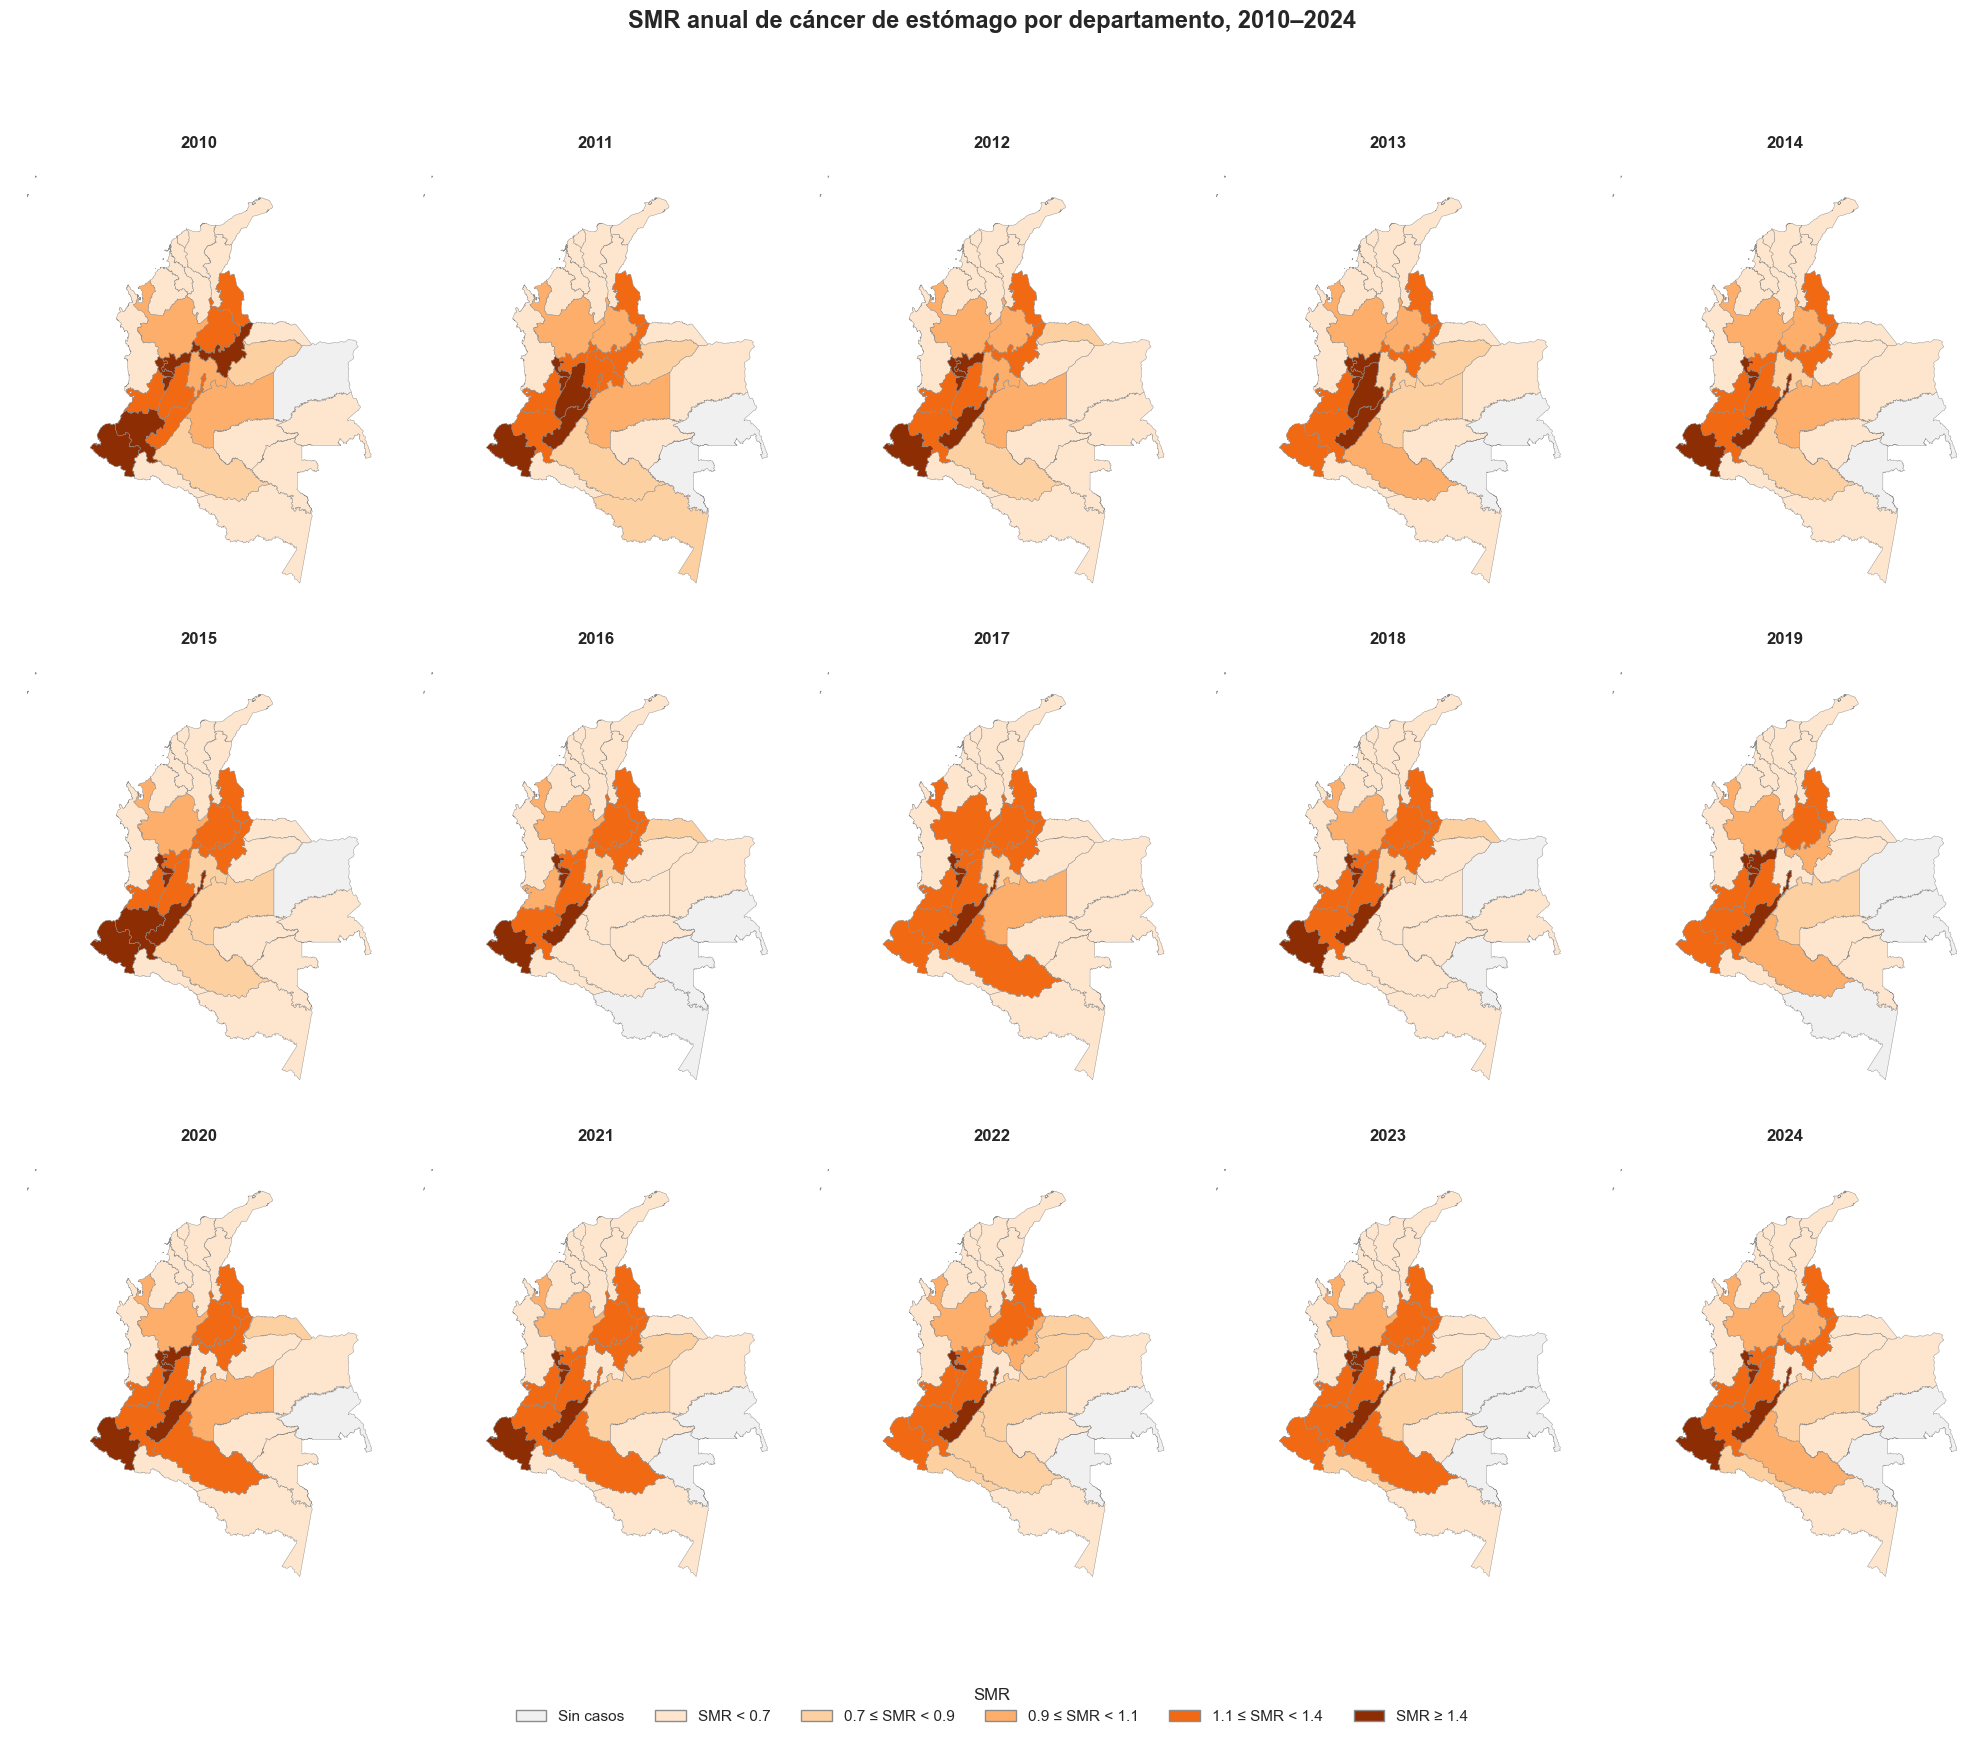

In [26]:
anos = list(range(2010, 2025))

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 18)
)

axes = axes.flatten()

for ax, ano in zip(axes, anos):
    mapa_smr = gdf_smr_anual[
        gdf_smr_anual["ANO"] == ano
    ].copy()

    for categoria, color in colores_smr.items():
        subset = mapa_smr[
            mapa_smr["Categoria_SMR"] == categoria
        ]

        if not subset.empty:
            subset.plot(
                ax=ax,
                color=color,
                edgecolor="#8c8c8c",
                linewidth=0.3,
                aspect=1
            )

    ax.set_title(
        str(ano),
        fontsize=12,
        fontweight="bold"
    )

    ax.axis("off")

leyenda = [
    Patch(
        facecolor=colores_smr[categoria],
        edgecolor="#8c8c8c",
        label=categoria
    )
    for categoria in orden_leyenda
]

fig.legend(
    handles=leyenda,
    title="SMR",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=6,
    frameon=False
)

fig.suptitle(
    "SMR anual de cáncer de estómago por departamento, 2010–2024",
    fontsize=17,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()

#### 3.4 Mapas quinquenales del SMR

Los siguientes mapas muestran la distribución espacial del SMR departamental durante los quinquenios 2010–2014, 2015–2019 y 2020–2024. La utilización de una misma clasificación en los tres periodos permite comparar la evolución del patrón espacial de mortalidad por cáncer de estómago.

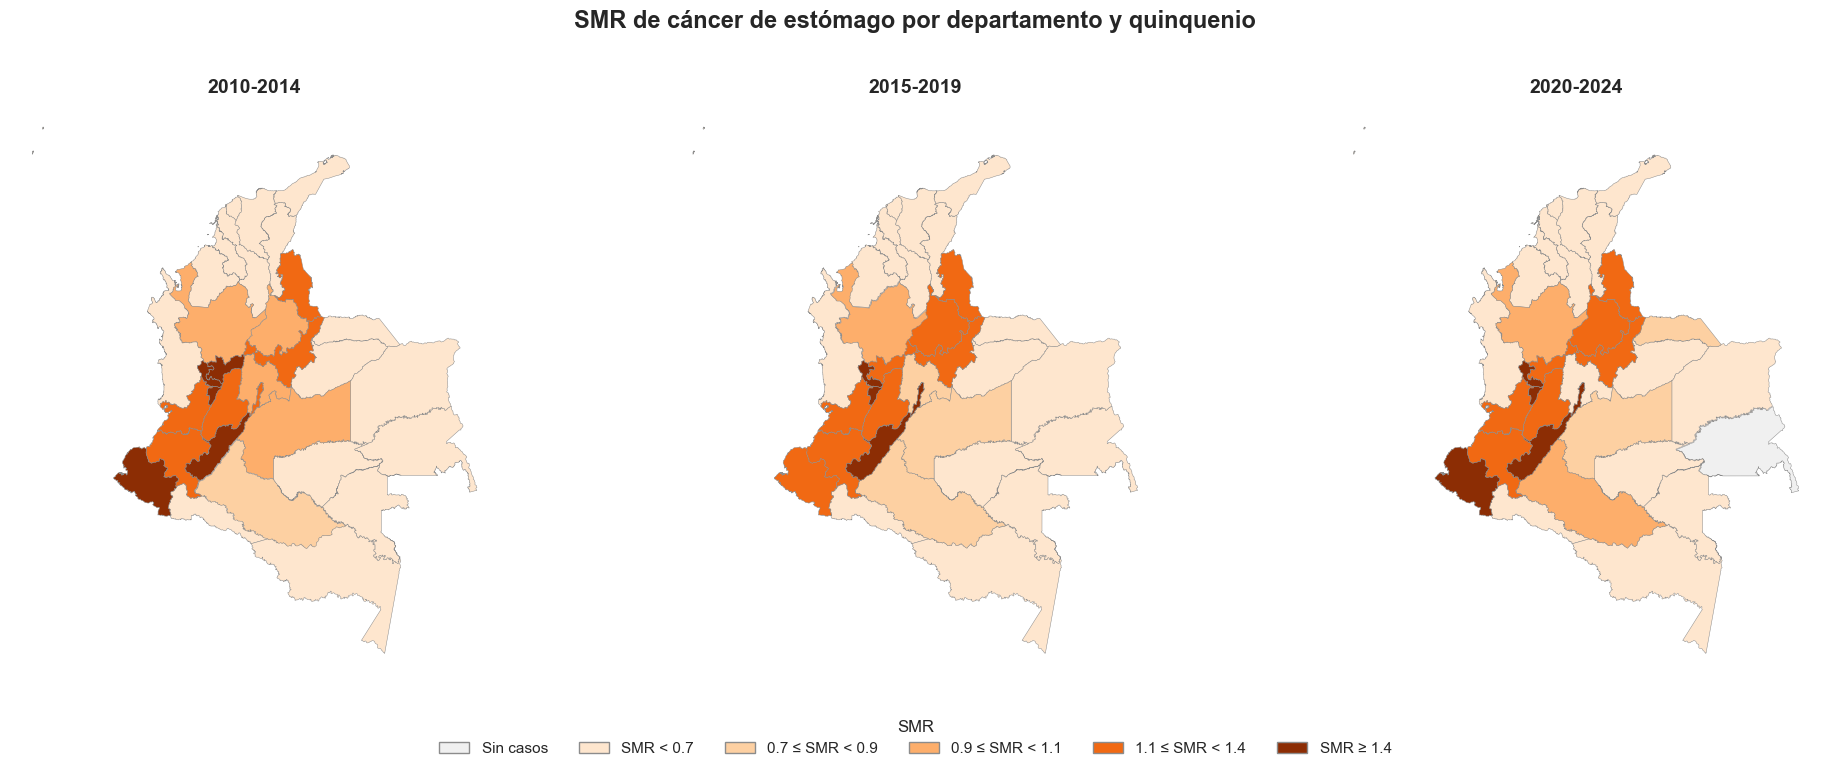

In [27]:
quinquenios = [
    "2010-2014",
    "2015-2019",
    "2020-2024"
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 8)
)

for ax, quinquenio in zip(axes, quinquenios):
    mapa_smr = gdf_smr_quinquenal[
        gdf_smr_quinquenal["Quinquenio"] == quinquenio
    ].copy()

    for categoria, color in colores_smr.items():
        subset = mapa_smr[
            mapa_smr["Categoria_SMR"] == categoria
        ]

        if not subset.empty:
            subset.plot(
                ax=ax,
                color=color,
                edgecolor="#8c8c8c",
                linewidth=0.35,
                aspect=1
            )

    ax.set_title(
        quinquenio,
        fontsize=14,
        fontweight="bold"
    )

    ax.axis("off")

leyenda = [
    Patch(
        facecolor=colores_smr[categoria],
        edgecolor="#8c8c8c",
        label=categoria
    )
    for categoria in orden_leyenda
]

fig.legend(
    handles=leyenda,
    title="SMR",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=6,
    frameon=False
)

fig.suptitle(
    "SMR de cáncer de estómago por departamento y quinquenio",
    fontsize=17,
    fontweight="bold",
    y=0.96
)

plt.tight_layout(rect=[0, 0.10, 1, 0.92])
plt.show()

## 4. Persistencia del exceso de mortalidad departamental

### 4.1 Identificación anual del exceso de mortalidad

Para evaluar la persistencia del exceso de mortalidad, se identifica inicialmente si el SMR departamental anual es superior a 1. Posteriormente, los resultados anuales se agrupan según los tres quinquenios del periodo de estudio.

Este procedimiento permite distinguir entre un exceso aislado en un año específico y un patrón que se mantiene durante varios periodos.

In [28]:
persistencia_anual = smr_departamento_anual.copy()

persistencia_anual["SMR_mayor_1"] = (
    persistencia_anual["SMR"] > 1
)

persistencia_anual["Quinquenio"] = pd.cut(
    persistencia_anual["ANO"],
    bins=[2009, 2014, 2019, 2024],
    labels=["2010-2014", "2015-2019", "2020-2024"]
)

In [29]:
indicador_anual_quinquenio = (
    persistencia_anual
    .groupby(
        ["dpto_ccdgo", "Quinquenio"],
        observed=True,
        as_index=False
    )
    .agg(
        Anos_SMR_mayor_1=("SMR_mayor_1", "sum"),
        Al_menos_un_ano_SMR_mayor_1=("SMR_mayor_1", "any")
    )
)

indicador_anual_quinquenio = indicador_anual_quinquenio.merge(
    nombres_departamentos,
    on="dpto_ccdgo",
    how="left",
    validate="many_to_one"
)

### 4.2 Persistencia del exceso de mortalidad por quinquenio

El indicador anual se complementa con el SMR calculado para cada quinquenio. Para cada departamento y periodo se evalúa conjuntamente la presencia de al menos un año con $SMR > 1$ y un $SMR$ quinquenal superior a 1.

A partir de estos dos componentes se construye un indicador de exceso de mortalidad para cada quinquenio.

In [30]:
indicador_persistencia = indicador_anual_quinquenio.merge(
    smr_departamento_quinquenal[
        ["dpto_ccdgo", "Quinquenio", "SMR"]
    ].rename(
        columns={"SMR": "SMR_quinquenal"}
    ),
    on=["dpto_ccdgo", "Quinquenio"],
    how="left",
    validate="one_to_one"
)

indicador_persistencia["Indicador_exceso"] = (
    indicador_persistencia["Al_menos_un_ano_SMR_mayor_1"]
    & (indicador_persistencia["SMR_quinquenal"] > 1)
)

In [31]:
tabla_indicador_persistencia = indicador_persistencia[
    [
        "DPNOM",
        "Quinquenio",
        "Anos_SMR_mayor_1",
        "SMR_quinquenal",
        "Indicador_exceso"
    ]
].copy()

tabla_indicador_persistencia = tabla_indicador_persistencia.rename(
    columns={
        "DPNOM": "Departamento",
        "Anos_SMR_mayor_1": "Años con SMR > 1",
        "SMR_quinquenal": "SMR quinquenal",
        "Indicador_exceso": "Exceso"
    }
)

tabla_indicador_persistencia["Exceso"] = (
    tabla_indicador_persistencia["Exceso"]
    .map({True: "Sí", False: "No"})
)

styled = (
    tabla_indicador_persistencia.style
    .hide(axis="index")
    .format({
        "SMR quinquenal": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Departamento,Quinquenio,Años con SMR > 1,SMR quinquenal,Exceso
Antioquia,2010-2014,2,1.01,Sí
Antioquia,2015-2019,4,1.06,Sí
Antioquia,2020-2024,5,1.06,Sí
Atlántico,2010-2014,0,0.40,No
Atlántico,2015-2019,0,0.53,No
Atlántico,2020-2024,0,0.50,No
"Bogotá, D.C.",2010-2014,5,1.33,Sí
"Bogotá, D.C.",2015-2019,5,1.42,Sí
"Bogotá, D.C.",2020-2024,5,1.43,Sí
Bolívar,2010-2014,0,0.34,No


### 4.3 Departamentos con exceso persistente de mortalidad

A partir del indicador definido previamente, se evalúa el número de quinquenios en los que cada departamento presenta exceso de mortalidad. Se considera persistente cuando el indicador de exceso se cumple en al menos dos de los tres quinquenios analizados.

Este criterio permite identificar los departamentos donde el exceso de mortalidad no corresponde únicamente a un periodo aislado, sino que se mantiene durante una parte importante del periodo de estudio.

In [32]:
persistencia_departamental = (
    indicador_persistencia
    .groupby(
        ["dpto_ccdgo", "DPNOM"],
        as_index=False
    )
    .agg(
        Quinquenios_exceso=("Indicador_exceso", "sum")
    )
)

persistencia_departamental["Persistente"] = (
    persistencia_departamental["Quinquenios_exceso"] >= 2
)

departamentos_persistentes = (
    persistencia_departamental[
        persistencia_departamental["Persistente"]
    ]
    .sort_values(
        ["Quinquenios_exceso", "dpto_ccdgo"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

In [33]:
tabla_persistencia = departamentos_persistentes[
    [
        "dpto_ccdgo",
        "DPNOM",
        "Quinquenios_exceso"
    ]
].copy()

tabla_persistencia = tabla_persistencia.rename(
    columns={
        "dpto_ccdgo": "Código",
        "DPNOM": "Departamento",
        "Quinquenios_exceso": "Quinquenios con exceso"
    }
)

styled = (
    tabla_persistencia.style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Código,Departamento,Quinquenios con exceso
05,Antioquia,3
11,"Bogotá, D.C.",3
15,Boyacá,3
17,Caldas,3
19,Cauca,3
41,Huila,3
52,Nariño,3
54,Norte de Santander,3
63,Quindío,3
66,Risaralda,3


### 4.4 Evolución anual del SMR en los departamentos de mayor riesgo

A partir de los departamentos que presentan exceso persistente de mortalidad, se seleccionan los cinco con mayor SMR promedio durante los tres quinquenios. Posteriormente, se analiza la evolución anual de su SMR entre 2010 y 2024.

Este análisis permite observar la estabilidad y las variaciones temporales del exceso de mortalidad en los departamentos con mayor riesgo.

In [34]:
top_5_departamentos = (
    departamentos_persistentes[
        ["dpto_ccdgo", "DPNOM", "Quinquenios_exceso"]
    ]
    .merge(
        smr_departamento_quinquenal.groupby(
            ["dpto_ccdgo", "DPNOM"],
            as_index=False
        ).agg(
            SMR_promedio=("SMR", "mean")
        ),
        on=["dpto_ccdgo", "DPNOM"],
        how="left",
        validate="one_to_one"
    )
    .sort_values(
        "SMR_promedio",
        ascending=False
    )
    .head(5)
    .reset_index(drop=True)
)

In [35]:
evolucion_top_5 = (
    smr_departamento_anual[
        smr_departamento_anual["dpto_ccdgo"].isin(
            top_5_departamentos["dpto_ccdgo"]
        )
    ]
    [
        ["ANO", "dpto_ccdgo", "SMR"]
    ]
    .merge(
        nombres_departamentos,
        on="dpto_ccdgo",
        how="left",
        validate="many_to_one"
    )
    .sort_values(
        ["dpto_ccdgo", "ANO"]
    )
    .reset_index(drop=True)
)

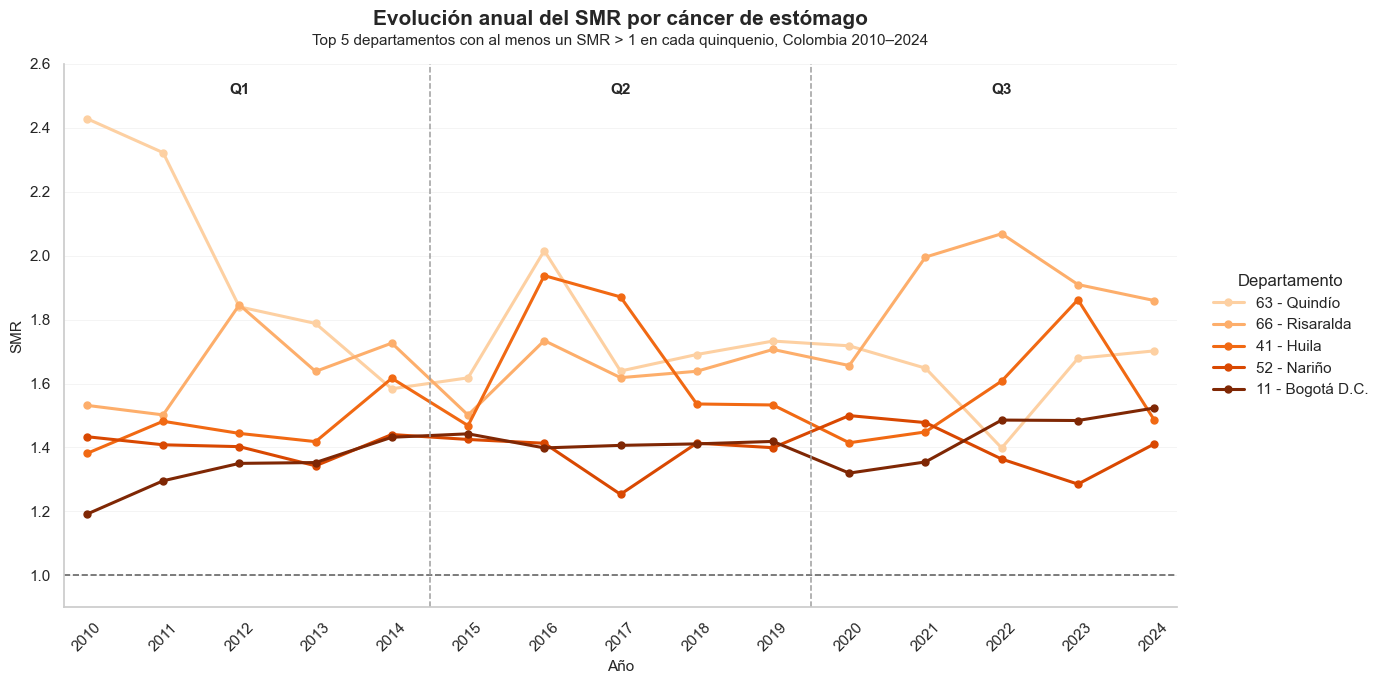

In [36]:
colores_top_5 = {
    "63": "#FDD0A2",
    "66": "#FDAE6B",
    "41": "#F16913",
    "52": "#D94801",
    "11": "#7F2704"
}

etiquetas_top_5 = {
    "63": "63 - Quindío",
    "66": "66 - Risaralda",
    "41": "41 - Huila",
    "52": "52 - Nariño",
    "11": "11 - Bogotá D.C."
}

orden_top_5 = ["63", "66", "41", "52", "11"]

fig, ax = plt.subplots(figsize=(14, 7))

for codigo in orden_top_5:
    datos = evolucion_top_5[
        evolucion_top_5["dpto_ccdgo"] == codigo
    ]

    ax.plot(
        datos["ANO"],
        datos["SMR"],
        color=colores_top_5[codigo],
        marker="o",
        markersize=5,
        linewidth=2.2,
        label=etiquetas_top_5[codigo]
    )

ax.axhline(
    y=1,
    color="#666666",
    linestyle="--",
    linewidth=1.2
)

for x in [2014.5, 2019.5]:
    ax.axvline(
        x=x,
        color="#9E9E9E",
        linestyle="--",
        linewidth=1.1
    )

ax.text(
    2012,
    2.52,
    "Q1",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold"
)

ax.text(
    2017,
    2.52,
    "Q2",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold"
)

ax.text(
    2022,
    2.52,
    "Q3",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    "Evolución anual del SMR por cáncer de estómago",
    fontsize=15,
    fontweight="bold",
    pad=28
)

ax.text(
    0.5,
    1.035,
    "Top 5 departamentos con al menos un SMR > 1 en cada quinquenio, Colombia 2010–2024",
    transform=ax.transAxes,
    ha="center",
    fontsize=11
)

ax.set_xlabel("Año", fontsize=11)
ax.set_ylabel("SMR", fontsize=11)

ax.set_xticks(range(2010, 2025))
ax.tick_params(axis="x", rotation=45)

ax.set_xlim(2009.7, 2024.3)
ax.set_ylim(0.9, 2.6)

ax.grid(
    axis="y",
    linestyle="-",
    linewidth=0.6,
    alpha=0.25
)

ax.grid(
    axis="x",
    visible=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Departamento",
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    frameon=False
)

plt.tight_layout()
plt.show()

### 4.5 Distribución espacial de los departamentos de mayor riesgo

Los cinco departamentos priorizados a partir de la persistencia del exceso de mortalidad y del SMR promedio quinquenal se representan espacialmente para identificar su distribución geográfica en Colombia.

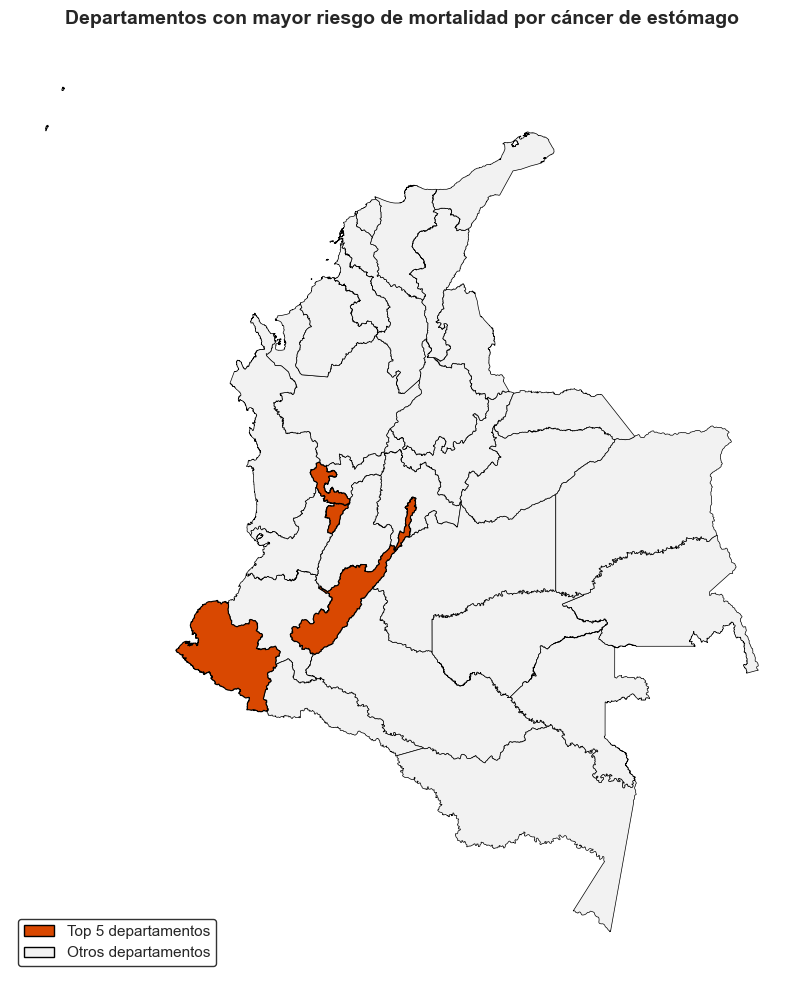

In [37]:
codigos_top_5 = top_5_departamentos["dpto_ccdgo"].tolist()

gdf_top_5 = gdf_departamentos.copy()

gdf_top_5["Departamento_riesgoso"] = np.where(
    gdf_top_5["DPTO_CCDGO"].isin(codigos_top_5),
    "Top 5",
    "Otros departamentos"
)

fig, ax = plt.subplots(figsize=(9, 10))

gdf_top_5[
    gdf_top_5["Departamento_riesgoso"] == "Otros departamentos"
].plot(
    ax=ax,
    color="#F2F2F2",
    edgecolor="black",
    linewidth=0.5
)

gdf_top_5[
    gdf_top_5["Departamento_riesgoso"] == "Top 5"
].plot(
    ax=ax,
    color="#D94801",
    edgecolor="black",
    linewidth=0.8
)

ax.set_title(
    "Departamentos con mayor riesgo de mortalidad por cáncer de estómago",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.axis("off")

leyenda = [
    Patch(
        facecolor="#D94801",
        edgecolor="black",
        label="Top 5 departamentos"
    ),
    Patch(
        facecolor="#F2F2F2",
        edgecolor="black",
        label="Otros departamentos"
    )
]

ax.legend(
    handles=leyenda,
    loc="lower left",
    frameon=True,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

## 5. Autocorrelación espacial

### 5.1 Construcción de la estructura de vecindad

La dependencia espacial entre los departamentos se representa mediante una estructura de vecindad construida a partir de sus límites geográficos. Esta estructura define qué departamentos se consideran vecinos y constituye la base para evaluar la autocorrelación espacial y, posteriormente, incorporar el efecto espacial estructurado en el modelo BYM2.

Antes del cálculo del índice de Moran se inspecciona la estructura resultante, incluyendo el número de vecinos por departamento, la presencia de unidades aisladas y la conectividad del grafo espacial.

In [38]:
gdf_vecindad = (
    gdf_departamentos[
        ["DPTO_CCDGO", "DPTO_CNMBR", "geometry"]
    ]
    .sort_values("DPTO_CCDGO")
    .reset_index(drop=True)
)

w_departamentos = Queen.from_dataframe(
    gdf_vecindad,
    ids="DPTO_CCDGO",
    use_index=False
)

numero_vecinos = pd.DataFrame({
    "dpto_ccdgo": list(w_departamentos.neighbors.keys()),
    "Numero_vecinos": [
        len(vecinos)
        for vecinos in w_departamentos.neighbors.values()
    ]
})

numero_vecinos = numero_vecinos.merge(
    gdf_vecindad[
        ["DPTO_CCDGO", "DPTO_CNMBR"]
    ],
    left_on="dpto_ccdgo",
    right_on="DPTO_CCDGO",
    how="left"
)

numero_vecinos = numero_vecinos[
    ["dpto_ccdgo", "DPTO_CNMBR", "Numero_vecinos"]
].sort_values(
    ["Numero_vecinos", "dpto_ccdgo"]
).reset_index(drop=True)

tabla_vecinos = (
    numero_vecinos
    .rename(
        columns={
            "dpto_ccdgo": "Código",
            "DPTO_CNMBR": "Departamento",
            "Numero_vecinos": "Número de vecinos"
        }
    )
)

styled = (
    tabla_vecinos.style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

C:\Users\USER\anaconda3\envs\EEG_EDA_ML\lib\site-packages\libpysal\weights\weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 88.
  warnings.warn(message)


Código,Departamento,Número de vecinos
88,"ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANTA CATALINA",0
08,ATLÁNTICO,2
44,LA GUAJIRA,2
52,NARIÑO,2
70,SUCRE,2
11,"BOGOTÁ, D.C.",3
23,CÓRDOBA,3
27,CHOCÓ,3
54,NORTE DE SANTANDER,3
63,QUINDÍO,3


In [39]:
componentes = w_departamentos.n_components
aislados = w_departamentos.islands

print(f"Número de componentes conexos: {componentes}")
print(f"Departamentos aislados: {aislados}")

Número de componentes conexos: 2
Departamentos aislados: ['88']


### 5.2 Índice global de Moran

El índice global de Moran permite evaluar si los valores del SMR presentan autocorrelación espacial, es decir, si departamentos geográficamente próximos tienden a presentar niveles de riesgo similares.

Para este análisis se utiliza la estructura de vecindad previamente construida. Debido a que San Andrés no presenta vecinos por contigüidad, el cálculo se realiza sobre el componente espacial conectado.

In [40]:
gdf_moran = gdf_vecindad[
    ~gdf_vecindad["DPTO_CCDGO"].isin(aislados)
].copy()

smr_moran = smr_departamento_quinquenal[
    ~smr_departamento_quinquenal["dpto_ccdgo"].isin(aislados)
].copy()

smr_moran = smr_moran.merge(
    gdf_moran[
        ["DPTO_CCDGO", "geometry"]
    ],
    left_on="dpto_ccdgo",
    right_on="DPTO_CCDGO",
    how="left",
    validate="many_to_one"
)

smr_moran = gpd.GeoDataFrame(
    smr_moran,
    geometry="geometry",
    crs=gdf_moran.crs
)

smr_moran = (
    smr_moran
    .sort_values(["Quinquenio", "dpto_ccdgo"])
    .reset_index(drop=True)
)

tabla_validacion_moran = (
    smr_moran
    .groupby("Quinquenio", observed=True)
    .agg(
        Departamentos=("dpto_ccdgo", "nunique"),
        SMR_faltantes=("SMR", lambda x: x.isna().sum()),
        Geometrias_faltantes=("geometry", lambda x: x.isna().sum())
    )
    .reset_index()
    .rename(
        columns={
            "Quinquenio": "Quinquenio",
            "Departamentos": "Departamentos",
            "SMR_faltantes": "SMR faltantes",
            "Geometrias_faltantes": "Geometrías faltantes"
        }
    )
)

styled = (
    tabla_validacion_moran.style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Quinquenio,Departamentos,SMR faltantes,Geometrías faltantes
2010-2014,32,0,0
2015-2019,32,0,0
2020-2024,32,0,0


In [41]:
w_moran = Queen.from_dataframe(
    gdf_moran,
    ids="DPTO_CCDGO",
    use_index=False
)

w_moran.transform = "r"

print(f"Número de departamentos: {w_moran.n}")
print(f"Número de componentes conexos: {w_moran.n_components}")
print(f"Departamentos aislados: {w_moran.islands}")

Número de departamentos: 32
Número de componentes conexos: 1
Departamentos aislados: []


In [42]:
resultados_moran = []

for quinquenio in ["2010-2014", "2015-2019", "2020-2024"]:
    datos_periodo = (
        smr_moran[
            smr_moran["Quinquenio"].astype(str) == quinquenio
        ]
        .set_index("dpto_ccdgo")
        .reindex(w_moran.id_order)
    )

    moran = Moran(
        datos_periodo["SMR"].to_numpy(),
        w_moran,
        permutations=9999
    )

    resultados_moran.append({
        "Quinquenio": quinquenio,
        "I de Moran": moran.I,
        "I esperado": moran.EI,
        "p-valor": moran.p_sim
    })

resultados_moran = pd.DataFrame(resultados_moran)

tabla_resultados_moran = resultados_moran.copy()

styled = (
    tabla_resultados_moran.style
    .hide(axis="index")
    .format({
        "I de Moran": "{:.4f}",
        "I esperado": "{:.4f}",
        "p-valor": "{:.4f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Quinquenio,I de Moran,I esperado,p-valor
2010-2014,0.5223,-0.0323,0.0001
2015-2019,0.4829,-0.0323,0.0001
2020-2024,0.4450,-0.0323,0.0002


## 6. Modelamiento jerárquico bayesiano espacial

### 6.1 Preparación de los datos para el modelo BYM2

El modelo BYM2 se plantea a partir del número de defunciones observadas y esperadas en cada unidad geográfica. Para cada departamento $i$, se considera:

$$
Y_i \mid \theta_i \sim \operatorname{Poisson}(E_i\theta_i)
$$

donde $Y_i$ corresponde al número de defunciones observadas, $E_i$ al número de defunciones esperadas y $\theta_i$ al riesgo relativo de mortalidad.

Como primera etapa se organiza la información departamental necesaria para el ajuste del modelo, conservando la correspondencia entre las unidades geográficas y la estructura espacial de vecindad.

In [43]:
datos_bym2 = (
    smr_departamento_quinquenal[
        smr_departamento_quinquenal["Quinquenio"].astype(str) == "2020-2024"
    ]
    [
        ["dpto_ccdgo", "DPNOM", "Observadas", "Esperadas", "SMR"]
    ]
    .sort_values("dpto_ccdgo")
    .reset_index(drop=True)
)

datos_bym2["Observadas"] = datos_bym2["Observadas"].astype(int)

print(f"Número de departamentos: {len(datos_bym2)}")
print(f"Defunciones observadas: {datos_bym2['Observadas'].sum():,}")
print(f"Defunciones esperadas: {datos_bym2['Esperadas'].sum():,.2f}")
print(f"Valores faltantes: {datos_bym2.isna().sum().sum()}")
print(f"Esperadas <= 0: {(datos_bym2['Esperadas'] <= 0).sum()}")

Número de departamentos: 33
Defunciones observadas: 26,418
Defunciones esperadas: 26,418.00
Valores faltantes: 0
Esperadas <= 0: 0


### 6.2 Estructura espacial para el modelo BYM2

El componente espacial estructurado del modelo BYM2 se define a partir de la relación de vecindad entre los departamentos. Esta estructura permite representar la dependencia espacial del riesgo, de manera que departamentos geográficamente conectados comparten información a través del efecto espacial estructurado.

Antes del ajuste del modelo se verifica la correspondencia entre las unidades incluidas en la base epidemiológica y la estructura de vecindad, así como la presencia de unidades geográficas aisladas.

In [44]:
codigos_bym2 = set(datos_bym2["dpto_ccdgo"])
codigos_geografia = set(gdf_vecindad["DPTO_CCDGO"])

sin_geometria = sorted(codigos_bym2 - codigos_geografia)
sin_datos = sorted(codigos_geografia - codigos_bym2)

w_bym2 = Queen.from_dataframe(
    gdf_vecindad,
    ids="DPTO_CCDGO",
    use_index=False
)

print(f"Unidades en datos BYM2: {len(codigos_bym2)}")
print(f"Unidades en estructura geográfica: {w_bym2.n}")
print(f"Datos sin geometría: {sin_geometria}")
print(f"Geometrías sin datos: {sin_datos}")
print(f"Componentes conexos: {w_bym2.n_components}")
print(f"Unidades aisladas: {w_bym2.islands}")

Unidades en datos BYM2: 33
Unidades en estructura geográfica: 33
Datos sin geometría: []
Geometrías sin datos: []
Componentes conexos: 2
Unidades aisladas: ['88']


C:\Users\USER\anaconda3\envs\EEG_EDA_ML\lib\site-packages\libpysal\weights\weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 88.
  warnings.warn(message)


### 6.3 Construcción del componente espacial estructurado

El componente espacial estructurado del modelo BYM2 se construye a partir de las 32 unidades geográficas conectadas. Para este componente se utiliza una estructura de vecindad tipo Queen y se construye la matriz de adyacencia $W$.

A partir del número de vecinos de cada departamento se define la matriz diagonal $D$ y posteriormente la matriz de precisión espacial:

$$
Q = D - W
$$

Esta matriz representa la estructura de dependencia espacial utilizada por el efecto ICAR del modelo BYM2. San Andrés se mantiene fuera de este componente estructurado debido a que no presenta vecinos por contigüidad.

In [45]:
codigos_conectados = [
    codigo
    for codigo in w_bym2.id_order
    if codigo not in w_bym2.islands
]

gdf_bym2_conectado = (
    gdf_vecindad[
        gdf_vecindad["DPTO_CCDGO"].isin(codigos_conectados)
    ]
    .set_index("DPTO_CCDGO")
    .loc[codigos_conectados]
    .reset_index()
)

w_bym2_conectado = Queen.from_dataframe(
    gdf_bym2_conectado,
    ids="DPTO_CCDGO",
    use_index=False
)

print(f"Unidades conectadas: {w_bym2_conectado.n}")
print(f"Componentes conexos: {w_bym2_conectado.n_components}")
print(f"Unidades aisladas: {w_bym2_conectado.islands}")
print(f"San Andrés incluido: {'88' in w_bym2_conectado.id_order}")

Unidades conectadas: 32
Componentes conexos: 1
Unidades aisladas: []
San Andrés incluido: False


#### 6.3.2 Matriz de precisión espacial

A partir de la estructura de vecindad del componente conectado se construye la matriz de adyacencia binaria $W$, donde cada elemento $w_{ij}$ toma el valor 1 cuando los departamentos $i$ y $j$ son vecinos y 0 en caso contrario.

Posteriormente se construye la matriz diagonal $D$, cuyos elementos corresponden al número de vecinos de cada departamento:

$$
D_{ii} = \sum_j w_{ij}
$$

La matriz de precisión espacial asociada al modelo ICAR se define como:

$$
Q = D - W
$$

In [46]:
orden_conectado = w_bym2_conectado.id_order

W_conn = pd.DataFrame(
    0,
    index=orden_conectado,
    columns=orden_conectado,
    dtype=float
)

for codigo, vecinos in w_bym2_conectado.neighbors.items():
    for vecino in vecinos:
        W_conn.loc[codigo, vecino] = 1.0

W_conn = W_conn.to_numpy()

D_conn = np.diag(W_conn.sum(axis=1))

Q_conn = D_conn - W_conn

print(f"Dimensión de W: {W_conn.shape}")
print(f"Dimensión de D: {D_conn.shape}")
print(f"Dimensión de Q: {Q_conn.shape}")
print(f"W simétrica: {np.allclose(W_conn, W_conn.T)}")
print(f"Diagonal de W igual a cero: {np.allclose(np.diag(W_conn), 0)}")
print(f"Suma de filas de Q igual a cero: {np.allclose(Q_conn.sum(axis=1), 0)}")
print(f"Rango de Q: {np.linalg.matrix_rank(Q_conn)}")

Dimensión de W: (32, 32)
Dimensión de D: (32, 32)
Dimensión de Q: (32, 32)
W simétrica: True
Diagonal de W igual a cero: True
Suma de filas de Q igual a cero: True
Rango de Q: 31


#### 6.3.3 Factor de escala del componente espacial

Debido a que la matriz de precisión del modelo ICAR es singular, se utiliza su inversa generalizada para obtener las varianzas marginales asociadas al componente espacial estructurado.

A partir de estas varianzas se calcula un factor de escala mediante su media geométrica:

$$
s = \exp\left(
\frac{1}{N}
\sum_{i=1}^{N}
\log\left(Q^{-}_{ii}\right)
\right)
$$

Este factor permite escalar el efecto espacial estructurado antes de incorporarlo en la parametrización BYM2.

In [47]:
Q_inv = np.linalg.pinv(Q_conn)

varianzas_marginales = np.diag(Q_inv)

scaling_factor = np.exp(
    np.mean(
        np.log(varianzas_marginales)
    )
)

print(f"Varianza mínima: {varianzas_marginales.min():.6f}")
print(f"Varianza máxima: {varianzas_marginales.max():.6f}")
print(f"Scaling factor: {scaling_factor:.6f}")

Varianza mínima: 0.162906
Varianza máxima: 0.876514
Scaling factor: 0.374120


#### 6.3.4 Lista de conexiones espaciales

La estructura de vecindad se representa mediante pares de índices que identifican las unidades geográficas conectadas. Cada relación entre dos departamentos se registra una única vez, evitando duplicar las conexiones del grafo.

Estos pares permiten incorporar la estructura de dependencia espacial del componente ICAR durante el ajuste del modelo.

In [48]:
indice_conectado = {
    codigo: i + 1
    for i, codigo in enumerate(w_bym2_conectado.id_order)
}

node1 = []
node2 = []

for codigo, vecinos in w_bym2_conectado.neighbors.items():
    i = indice_conectado[codigo]

    for vecino in vecinos:
        j = indice_conectado[vecino]

        if i < j:
            node1.append(i)
            node2.append(j)

node1 = np.array(node1, dtype=int)
node2 = np.array(node2, dtype=int)

print(f"Número de conexiones: {len(node1)}")
print(f"Longitud de node1: {len(node1)}")
print(f"Longitud de node2: {len(node2)}")
print(f"Índice mínimo: {min(node1.min(), node2.min())}")
print(f"Índice máximo: {max(node1.max(), node2.max())}")
print(f"Conexiones duplicadas: {len(node1) - len(set(zip(node1, node2)))}")

Número de conexiones: 74
Longitud de node1: 74
Longitud de node2: 74
Índice mínimo: 1
Índice máximo: 32
Conexiones duplicadas: 0


### 6.4 Preparación de los datos de entrada del modelo

Una vez definida la estructura espacial, se organizan los datos epidemiológicos y geográficos requeridos para el ajuste del modelo BYM2.

Las defunciones observadas y esperadas se mantienen para las 33 unidades geográficas. Las 32 unidades pertenecientes al componente conectado se asocian con la estructura espacial ICAR, mientras que San Andrés se identifica de forma independiente debido a su ausencia de vecinos por contigüidad.

Finalmente, se integran las observaciones, los valores esperados, las conexiones espaciales y el factor de escala en una única estructura de entrada para el modelo.

In [49]:
orden_bym2 = w_bym2.id_order

datos_bym2_ordenados = (
    datos_bym2
    .set_index("dpto_ccdgo")
    .reindex(orden_bym2)
    .reset_index()
)

idx_conectados = np.array(
    [
        i + 1
        for i, codigo in enumerate(orden_bym2)
        if codigo != "88"
    ],
    dtype=int
)

idx_aislado = int(
    orden_bym2.index("88") + 1
)

Y = datos_bym2_ordenados["Observadas"].to_numpy(dtype=int)
E = datos_bym2_ordenados["Esperadas"].to_numpy(dtype=float)

Y_conn = Y[idx_conectados - 1]
E_conn = E[idx_conectados - 1]

Y_aislado = Y[idx_aislado - 1]
E_aislado = E[idx_aislado - 1]

print(f"Unidades geográficas: {len(Y)}")
print(f"Unidades conectadas: {len(idx_conectados)}")
print(f"Unidades aisladas: {len(Y) - len(idx_conectados)}")
print(f"Unidad aislada: {orden_bym2[idx_aislado - 1]}")
print(f"Defunciones observadas totales: {Y.sum():,}")
print(f"Defunciones esperadas totales: {E.sum():,.2f}")
print(f"Valores faltantes: {np.isnan(E).sum()}")

Unidades geográficas: 33
Unidades conectadas: 32
Unidades aisladas: 1
Unidad aislada: 88
Defunciones observadas totales: 26,418
Defunciones esperadas totales: 26,418.00
Valores faltantes: 0


### 6.5 Especificación del modelo BYM2

El riesgo relativo de mortalidad se modela mediante una distribución de Poisson, utilizando el número esperado de defunciones como referencia:

$$
Y_i \mid \theta_i \sim \operatorname{Poisson}(E_i\theta_i)
$$

El logaritmo del riesgo relativo se expresa mediante la parametrización BYM2:

$$\log(\theta_i)=\alpha+\sigma\left(\sqrt{1-\rho}\,v_i+\sqrt{\frac{\rho}{s}}\,u_i\right)$$

donde $\alpha$ representa el nivel general de riesgo, $v_i$ corresponde al efecto espacial no estructurado, $u_i$ al efecto espacial estructurado, $\sigma$ controla la variabilidad total de los efectos espaciales, $\rho$ determina la proporción de dicha variabilidad atribuible al componente espacial estructurado y $s$ corresponde al factor de escala calculado previamente.

Para la unidad geográfica aislada, el efecto espacial se modela de manera independiente debido a la ausencia de vecinos por contigüidad.

#### 6.5.1 Distribuciones a priori

Para completar la especificación bayesiana del modelo se asignan distribuciones a priori a sus parámetros principales:

$$
\alpha \sim \mathcal{N}(0,5)
$$

$$
\sigma \sim t_3^{+}(0,1)
$$

$$
\rho \sim \operatorname{Beta}(0.5,0.5)
$$

El intercepto $\alpha$ representa el nivel general del riesgo en la escala logarítmica. El parámetro $\sigma$ controla la magnitud global de la variabilidad espacial, mientras que $\rho$ determina la proporción de esta variabilidad atribuible al componente espacial estructurado.

Los efectos no estructurados se modelan mediante:

$$
v_i \sim \mathcal{N}(0,1)
$$

mientras que el componente espacial estructurado sigue una distribución ICAR definida por la estructura de vecindad construida previamente.

### 6.6 Ajuste del modelo BYM2

El modelo BYM2 se estima mediante inferencia bayesiana utilizando muestreo Hamiltoniano. La implementación computacional se realiza con Stan desde Python, conservando la estructura espacial, el factor de escala y las distribuciones a priori definidas previamente.

#### 6.6.1 Implementación computacional del modelo

In [50]:
modelo_bym2_codigo = r"""
functions {
    real icar_normal_lpdf(vector phi, int N, array[] int node1, array[] int node2) {
        return -0.5 * dot_self(phi[node1] - phi[node2])
               + normal_lpdf(sum(phi) | 0, 0.001 * N);
    }
}

data {
    int<lower=1> N;
    int<lower=1> N_conn;
    int<lower=1> N_edges;

    array[N] int<lower=0> Y;
    vector<lower=0>[N] E;

    array[N_conn] int<lower=0> Y_conn;
    vector<lower=0>[N_conn] E_conn;

    int<lower=0> Y_island;
    real<lower=0> E_island;

    array[N_edges] int<lower=1, upper=N_conn> node1;
    array[N_edges] int<lower=1, upper=N_conn> node2;

    real<lower=0> scaling_factor;

    array[N_conn] int<lower=1, upper=N> idx_conn;
    int<lower=1, upper=N> idx_island;
}

parameters {
    real alpha;
    real<lower=0> sigma;
    real<lower=0, upper=1> rho;

    vector[N_conn] phi_conn;
    real phi_island;

    vector[N] delta;
}

transformed parameters {
    vector[N] phi;
    vector[N] efecto_espacial;
    vector[N] log_rr;
    vector[N] rr;

    phi = rep_vector(0, N);
    phi[idx_conn] = phi_conn;
    phi[idx_island] = phi_island;

    efecto_espacial =
        sigma * (
            sqrt(rho / scaling_factor) * phi
            + sqrt(1 - rho) * delta
        );

    log_rr = alpha + efecto_espacial;
    rr = exp(log_rr);
}

model {
    alpha ~ normal(0, 5);
    sigma ~ student_t(3, 0, 1);
    rho ~ beta(0.5, 0.5);

    phi_conn ~ icar_normal(N_conn, node1, node2);
    phi_island ~ normal(0, 1);
    delta ~ normal(0, 1);

    Y ~ poisson_log(log(E) + log_rr);
}
"""

ruta_modelo_bym2 = RUTA_SRC / "bym2_estomago.stan"

ruta_modelo_bym2.write_text(
    modelo_bym2_codigo,
    encoding="utf-8"
)

print(f"Modelo guardado en: {ruta_modelo_bym2}")

Modelo guardado en: C:\Users\USER\Desktop\Tesis\src\bym2_estomago.stan


In [51]:
datos_modelo = {
    "N": len(Y),
    "N_conn": len(Y_conn),
    "N_edges": len(node1),
    "Y": Y.tolist(),
    "E": E.tolist(),
    "Y_conn": Y_conn.tolist(),
    "E_conn": E_conn.tolist(),
    "Y_island": int(Y_aislado),
    "E_island": float(E_aislado),
    "node1": node1.tolist(),
    "node2": node2.tolist(),
    "scaling_factor": float(scaling_factor),
    "idx_conn": idx_conectados.tolist(),
    "idx_island": int(idx_aislado)
}

print(f"N: {datos_modelo['N']}")
print(f"N conectados: {datos_modelo['N_conn']}")
print(f"Conexiones: {datos_modelo['N_edges']}")
print(f"Observadas: {sum(datos_modelo['Y']):,}")
print(f"Esperadas: {sum(datos_modelo['E']):,.2f}")
print(f"Factor de escala: {datos_modelo['scaling_factor']:.6f}")

N: 33
N conectados: 32
Conexiones: 74
Observadas: 26,418
Esperadas: 26,418.00
Factor de escala: 0.374120


#### 6.6.2 Compilación del modelo

In [52]:
modelo_bym2 = CmdStanModel(
    stan_file=str(ruta_modelo_bym2)
)

print("Modelo BYM2 compilado correctamente.")

21:01:09 - cmdstanpy - INFO - compiling stan file C:\Users\USER\Desktop\Tesis\src\bym2_estomago.stan to exe file C:\Users\USER\Desktop\Tesis\src\bym2_estomago.exe
21:01:56 - cmdstanpy - INFO - compiled model executable: C:\Users\USER\Desktop\Tesis\src\bym2_estomago.exe


Modelo BYM2 compilado correctamente.


#### 6.6.3 Muestreo posterior

In [53]:
ajuste_bym2 = modelo_bym2.sample(
    data=datos_modelo,
    chains=4,
    parallel_chains=4,
    iter_warmup=1000,
    iter_sampling=1000,
    adapt_delta=0.99,
    max_treedepth=15,
    seed=1234,
    show_progress=True
)

21:01:57 - cmdstanpy - INFO - CmdStan start processing


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

21:02:15 - cmdstanpy - INFO - CmdStan done processing.


#### 6.6.4 Diagnóstico de convergencia

In [54]:
diagnostico_bym2 = ajuste_bym2.diagnose()

print(diagnostico_bym2)

Processing csv files: C:\Users\USER\AppData\Local\Temp\tmpe9de4a8j\bym2_estomago_1py0ybb\bym2_estomago-20261016210157_1.csv, C:\Users\USER\AppData\Local\Temp\tmpe9de4a8j\bym2_estomago_1py0ybb\bym2_estomago-20261016210157_2.csv, C:\Users\USER\AppData\Local\Temp\tmpe9de4a8j\bym2_estomago_1py0ybb\bym2_estomago-20261016210157_3.csv, C:\Users\USER\AppData\Local\Temp\tmpe9de4a8j\bym2_estomago_1py0ybb\bym2_estomago-20261016210157_4.csv

Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
E-BFMI satisfactory.

Effective sample size satisfactory.

Split R-hat values satisfactory all parameters.

Processing complete, no problems detected.



In [55]:
resumen_bym2 = ajuste_bym2.summary()

print(resumen_bym2.columns.tolist())

['Mean', 'MCSE', 'StdDev', '5%', '50%', '95%', 'N_Eff', 'N_Eff/s', 'R_hat']


In [56]:
resumen_parametros = (
    resumen_bym2
    .loc[
        ["alpha", "sigma", "rho"],
        ["Mean", "50%", "StdDev", "N_Eff", "R_hat"]
    ]
    .rename(
        columns={
            "Mean": "Media",
            "50%": "Mediana",
            "StdDev": "DE",
            "N_Eff": "ESS",
            "R_hat": "R-hat"
        }
    )
)

resumen_parametros

,Media,Mediana,DE,ESS,R-hat
alpha,-0.52,-0.51,0.06,"4,295.75",1.00
sigma,0.86,0.85,0.13,"1,251.70",1.00
rho,0.92,0.96,0.11,439.26,1.01


In [57]:
tabla_parametros = resumen_parametros.reset_index().rename(
    columns={"index": "Parámetro"}
)

styled = (
    tabla_parametros.style
    .hide(axis="index")
    .format({
        "Media": "{:.3f}",
        "Mediana": "{:.3f}",
        "DE": "{:.3f}",
        "ESS": "{:.2f}",
        "R-hat": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Parámetro"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Parámetro,Media,Mediana,DE,ESS,R-hat
alpha,-0.516,-0.515,0.055,4295.75,1.00
sigma,0.863,0.850,0.130,1251.70,1.00
rho,0.915,0.962,0.115,439.26,1.01


### 6.7 Estimación posterior del riesgo relativo

In [58]:
rr_draws = ajuste_bym2.stan_variable("rr")

print(f"Muestras posteriores: {rr_draws.shape[0]:,}")
print(f"Departamentos: {rr_draws.shape[1]}")

Muestras posteriores: 4,000
Departamentos: 33


In [59]:
resultados_rr = datos_bym2_ordenados[
    ["dpto_ccdgo", "DPNOM"]
].copy()

resultados_rr["RR_media"] = rr_draws.mean(axis=0)
resultados_rr["RR_mediana"] = np.median(rr_draws, axis=0)
resultados_rr["IC95_inf"] = np.quantile(rr_draws, 0.025, axis=0)
resultados_rr["IC95_sup"] = np.quantile(rr_draws, 0.975, axis=0)
resultados_rr["P_RR_gt_1"] = (rr_draws > 1).mean(axis=0)

resultados_rr = (
    resultados_rr
    .sort_values("RR_media", ascending=False)
    .reset_index(drop=True)
)

resultados_rr.head()

,dpto_ccdgo,DPNOM,RR_media,RR_mediana,IC95_inf,IC95_sup,P_RR_gt_1
0,66,Risaralda,1.89,1.89,1.77,2.02,1.00
1,63,Quindío,1.63,1.63,1.48,1.78,1.00
2,41,Huila,1.56,1.56,1.47,1.66,1.00
3,11,"Bogotá, D.C.",1.43,1.43,1.39,1.47,1.00
4,52,Nariño,1.41,1.41,1.33,1.49,1.00


In [60]:
tabla_rr_top10 = (
    resultados_rr.head(10)
    .rename(
        columns={
            "dpto_ccdgo": "Código",
            "DPNOM": "Departamento",
            "RR_media": "RR medio",
            "RR_mediana": "RR mediano",
            "IC95_inf": "IC 95% inferior",
            "IC95_sup": "IC 95% superior",
            "P_RR_gt_1": "P(RR > 1)"
        }
    )
)

styled = (
    tabla_rr_top10.style
    .hide(axis="index")
    .format({
        "RR medio": "{:.2f}",
        "RR mediano": "{:.2f}",
        "IC 95% inferior": "{:.2f}",
        "IC 95% superior": "{:.2f}",
        "P(RR > 1)": "{:.4f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Código,Departamento,RR medio,RR mediano,IC 95% inferior,IC 95% superior,P(RR > 1)
66,Risaralda,1.89,1.89,1.77,2.02,1.0000
63,Quindío,1.63,1.63,1.48,1.78,1.0000
41,Huila,1.56,1.56,1.47,1.66,1.0000
11,"Bogotá, D.C.",1.43,1.43,1.39,1.47,1.0000
52,Nariño,1.41,1.41,1.33,1.49,1.0000
17,Caldas,1.30,1.30,1.20,1.40,1.0000
54,Norte de Santander,1.25,1.25,1.18,1.33,1.0000
73,Tolima,1.24,1.24,1.16,1.33,1.0000
76,Valle del Cauca,1.24,1.24,1.19,1.28,1.0000
19,Cauca,1.23,1.23,1.15,1.30,1.0000


### 6.8 Distribución espacial de la probabilidad posterior de exceso de riesgo

In [61]:
gdf_rr_posterior = gdf_departamentos.merge(
    resultados_rr,
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left"
)

print(f"Departamentos en el mapa: {len(gdf_rr_posterior)}")
print(f"Departamentos sin RR posterior: {gdf_rr_posterior['RR_media'].isna().sum()}")
print(f"Departamentos sin P(RR > 1): {gdf_rr_posterior['P_RR_gt_1'].isna().sum()}")

Departamentos en el mapa: 33
Departamentos sin RR posterior: 0
Departamentos sin P(RR > 1): 0


In [62]:
bins_prob = [-0.001, 0.05, 0.20, 0.80, 0.95, 1.001]

labels_prob = [
    "< 0.05",
    "0.05 - 0.20",
    "0.20 - 0.80",
    "0.80 - 0.95",
    "> 0.95"
]

gdf_rr_posterior["Probabilidad_exceso"] = pd.cut(
    gdf_rr_posterior["P_RR_gt_1"],
    bins=bins_prob,
    labels=labels_prob,
    include_lowest=True,
    right=False
)

gdf_rr_posterior["Probabilidad_exceso"].value_counts().sort_index()

Probabilidad_exceso
< 0.05         19
0.05 - 0.20     0
0.20 - 0.80     0
0.80 - 0.95     1
> 0.95         13
Name: count, dtype: int64

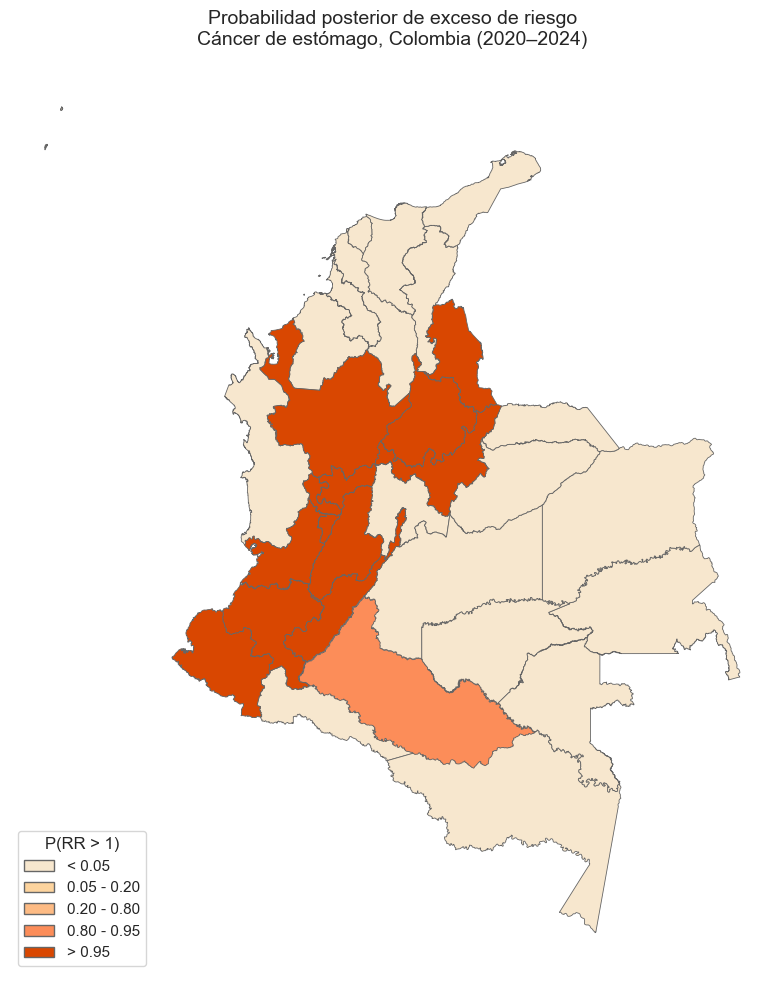

In [63]:
from matplotlib.patches import Patch

colores_prob = {
    "< 0.05": "#F7E7CE",
    "0.05 - 0.20": "#FDD49E",
    "0.20 - 0.80": "#FDBB84",
    "0.80 - 0.95": "#FC8D59",
    "> 0.95": "#D94701"
}

fig, ax = plt.subplots(figsize=(9, 10))

for categoria in labels_prob:
    subset = gdf_rr_posterior[
        gdf_rr_posterior["Probabilidad_exceso"] == categoria
    ]

    if not subset.empty:
        subset.plot(
            ax=ax,
            color=colores_prob[categoria],
            edgecolor="#666666",
            linewidth=0.6
        )

leyenda = [
    Patch(
        facecolor=colores_prob[categoria],
        edgecolor="#666666",
        label=categoria
    )
    for categoria in labels_prob
]

ax.legend(
    handles=leyenda,
    title="P(RR > 1)",
    loc="lower left",
    frameon=True
)

ax.set_title(
    "Probabilidad posterior de exceso de riesgo\nCáncer de estómago, Colombia (2020–2024)",
    fontsize=14,
    pad=15
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 7. Incorporación de covariables al modelo espacial

### 7.1 IPM

In [64]:
columnas_ipm = [
    "DPTO_CCDGO",
    "DPTO_CNMBR",
    "MPIO_CCDGO",
    "MPIO_CNMBR",
    "MPM",
    "MPM_CAB",
    "MPM_CPRD"
]

display(ipm_2018[columnas_ipm].head(10))

print("\nTipos de datos:")
print(ipm_2018[columnas_ipm].dtypes)

print("\nDepartamentos:", ipm_2018["DPTO_CCDGO"].nunique())
print("Municipios:", len(ipm_2018))
print("Faltantes en MPM:", ipm_2018["MPM"].isna().sum())

,DPTO_CCDGO,DPTO_CNMBR,MPIO_CCDGO,MPIO_CNMBR,MPM,MPM_CAB,MPM_CPRD
0,18,CAQUETÃ,001,FLORENCIA,29.60,27.20,53.30
1,18,CAQUETÃ,029,ALBANIA,38.80,26.60,48.90
2,18,CAQUETÃ,094,BELÃN DE LOS ANDAQUÃES,50.00,41.40,66.10
3,18,CAQUETÃ,247,EL DONCELLO,44.30,37.60,60.70
4,18,CAQUETÃ,256,EL PAUJÃL,45.50,40.30,53.40
5,18,CAQUETÃ,410,LA MONTAÃITA,56.20,34.90,61.50
6,18,CAQUETÃ,460,MILÃN,64.60,38.10,68.70
7,18,CAQUETÃ,479,MORELIA,42.40,33.60,53.00
8,18,CAQUETÃ,610,SAN JOSÃ DEL FRAGUA,48.70,41.60,57.60
9,18,CAQUETÃ,860,VALPARAÃSO,50.00,35.60,59.10



Tipos de datos:
DPTO_CCDGO     object
DPTO_CNMBR     object
MPIO_CCDGO     object
MPIO_CNMBR     object
MPM           float64
MPM_CAB       float64
MPM_CPRD      float64
dtype: object

Departamentos: 33
Municipios: 1122
Faltantes en MPM: 0


In [65]:
poblacion_2018 = poblacion_mun[
    poblacion_mun["ANO"] == 2018
].copy()

print("Registros población 2018:", len(poblacion_2018))
print("Departamentos:", poblacion_2018["dpto_ccdgo"].nunique())
print("Municipios:", poblacion_2018["DPMP"].nunique())
print("Faltantes población:", poblacion_2018["Total"].isna().sum())

display(poblacion_2018.head())

Registros población 2018: 1123
Departamentos: 33
Municipios: 1040
Faltantes población: 0


,dpto_ccdgo,DPNOM,mpio_cdpmp,DPMP,ANO,Total,Hombres,Mujeres,menor_40,40_44,45_49,50_54,55_59,60_64,65_69,70_74,75_79,80_84,mayor_84
10,5,Antioquia,5001,Medellín,2018,2427133,1141343,1285790,1471498,146356,143656,152416,138677,113591,88912,64995,45755,30731,30546
27,5,Antioquia,5002,Abejorral,2018,20368,10494,9874,11776,1256,1224,1241,1219,1110,892,653,465,299,233
44,5,Antioquia,5004,Abriaquí,2018,2718,1463,1255,1657,159,153,156,143,115,89,77,63,45,61
61,5,Antioquia,5021,Alejandría,2018,4642,2313,2329,2835,247,252,267,258,217,174,134,104,76,78
78,5,Antioquia,5030,Amagá,2018,30230,14850,15380,18398,1829,1871,1961,1793,1449,1070,750,507,321,281


In [66]:
ipm_cruce = ipm_2018[
    ["DPTO_CCDGO", "MPIO_CCDGO", "MPIO_CNMBR", "MPM"]
].copy()

ipm_cruce["codigo_municipio"] = (
    ipm_cruce["DPTO_CCDGO"].astype(str).str.zfill(2)
    + ipm_cruce["MPIO_CCDGO"].astype(str).str.zfill(3)
)

poblacion_cruce = poblacion_2018[
    ["dpto_ccdgo", "mpio_cdpmp", "DPMP", "Total"]
].copy()

poblacion_cruce["codigo_municipio"] = (
    poblacion_cruce["mpio_cdpmp"]
    .astype(int)
    .astype(str)
    .str.zfill(5)
)

comparacion_ipm = ipm_cruce.merge(
    poblacion_cruce,
    on="codigo_municipio",
    how="outer",
    indicator=True
)

print(comparacion_ipm["_merge"].value_counts())

display(
    comparacion_ipm[
        comparacion_ipm["_merge"] != "both"
    ]
)

_merge
both          1122
right_only       1
left_only        0
Name: count, dtype: int64


,DPTO_CCDGO,MPIO_CCDGO,MPIO_CNMBR,MPM,codigo_municipio,dpto_ccdgo,mpio_cdpmp,DPMP,Total,_merge
595,NaN,NaN,NaN,NaN,27493,27,27493,Nuevo Belén de Bajirá,0,right_only


In [67]:
ipm_poblacion = ipm_cruce.merge(
    poblacion_cruce[
        ["codigo_municipio", "Total"]
    ],
    on="codigo_municipio",
    how="left"
)

ipm_poblacion["MPM_ponderado"] = (
    ipm_poblacion["MPM"] * ipm_poblacion["Total"]
)

ipm_departamental_2018 = (
    ipm_poblacion
    .groupby("DPTO_CCDGO", as_index=False)
    .agg(
        Poblacion_2018=("Total", "sum"),
        Suma_MPM_ponderado=("MPM_ponderado", "sum")
    )
)

ipm_departamental_2018["IPM_2018"] = (
    ipm_departamental_2018["Suma_MPM_ponderado"]
    / ipm_departamental_2018["Poblacion_2018"]
)

ipm_departamental_2018 = (
    ipm_departamental_2018[
        ["DPTO_CCDGO", "Poblacion_2018", "IPM_2018"]
    ]
    .merge(
        datos_bym2_ordenados[
            ["dpto_ccdgo", "DPNOM"]
        ],
        left_on="DPTO_CCDGO",
        right_on="dpto_ccdgo",
        how="left"
    )
    [["DPTO_CCDGO", "DPNOM", "Poblacion_2018", "IPM_2018"]]
    .sort_values("IPM_2018", ascending=False)
    .reset_index(drop=True)
)

print("Departamentos:", len(ipm_departamental_2018))
print("Faltantes IPM:", ipm_departamental_2018["IPM_2018"].isna().sum())

display(ipm_departamental_2018)

Departamentos: 33
Faltantes IPM: 0


,DPTO_CCDGO,DPNOM,Poblacion_2018,IPM_2018
0,99,Vichada,107702,80.50
1,97,Vaupés,40774,79.10
2,94,Guainía,48081,75.17
3,27,Chocó,534807,63.62
4,91,Amazonas,76573,60.37
5,44,La Guajira,880552,60.05
6,95,Guaviare,82768,47.49
7,70,Sucre,904850,46.42
8,23,Córdoba,1784754,44.77
9,18,Caquetá,402085,44.23


In [68]:
ipm_modelo = (
    datos_bym2_ordenados[
        ["dpto_ccdgo", "DPNOM"]
    ]
    .merge(
        ipm_departamental_2018[
            ["DPTO_CCDGO", "IPM_2018"]
        ],
        left_on="dpto_ccdgo",
        right_on="DPTO_CCDGO",
        how="left"
    )
    .drop(columns="DPTO_CCDGO")
)

ipm_modelo["IPM_2018_std"] = (
    (ipm_modelo["IPM_2018"] - ipm_modelo["IPM_2018"].mean())
    / ipm_modelo["IPM_2018"].std()
)

print("Departamentos:", len(ipm_modelo))
print("Faltantes:", ipm_modelo["IPM_2018_std"].isna().sum())
print("Media estandarizada:", ipm_modelo["IPM_2018_std"].mean())
print("DE estandarizada:", ipm_modelo["IPM_2018_std"].std())

display(ipm_modelo)

Departamentos: 33
Faltantes: 0
Media estandarizada: -4.306319610667274e-16
DE estandarizada: 1.0


,dpto_ccdgo,DPNOM,IPM_2018,IPM_2018_std
0,05,Antioquia,21.98,-0.84
1,08,Atlántico,22.80,-0.79
2,11,"Bogotá, D.C.",9.00,-1.53
3,13,Bolívar,37.87,0.01
4,15,Boyacá,25.73,-0.64
5,17,Caldas,22.81,-0.79
6,18,Caquetá,44.23,0.35
7,19,Cauca,38.24,0.03
8,20,Cesar,38.51,0.05
9,23,Córdoba,44.77,0.38


In [69]:
datos_modelo_ipm = datos_modelo.copy()

datos_modelo_ipm["X_ipm"] = (
    ipm_modelo["IPM_2018_std"]
    .to_numpy()
    .astype(float)
    .tolist()
)

print("N del modelo:", datos_modelo_ipm["N"])
print("Valores de IPM:", len(datos_modelo_ipm["X_ipm"]))
print("Faltantes:", np.isnan(datos_modelo_ipm["X_ipm"]).sum())
print("Media:", np.mean(datos_modelo_ipm["X_ipm"]))
print("DE:", np.std(datos_modelo_ipm["X_ipm"], ddof=1))

N del modelo: 33
Valores de IPM: 33
Faltantes: 0
Media: -4.306319610667274e-16
DE: 1.0


In [70]:
ruta_modelo_ipm = RUTA_SRC / "bym2_estomago_ipm.stan"

modelo_bym2_ipm = CmdStanModel(
    stan_file=str(ruta_modelo_ipm)
)

print("Modelo BYM2 + IPM compilado correctamente.")

Modelo BYM2 + IPM compilado correctamente.


In [71]:
ajuste_bym2_ipm = modelo_bym2_ipm.sample(
    data=datos_modelo_ipm,
    chains=4,
    parallel_chains=4,
    iter_warmup=1000,
    iter_sampling=1000,
    adapt_delta=0.99,
    max_treedepth=15,
    seed=1234,
    show_progress=True
)

21:02:21 - cmdstanpy - INFO - CmdStan start processing


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

21:02:44 - cmdstanpy - INFO - CmdStan done processing.


In [72]:
print(ajuste_bym2_ipm.diagnose())

Processing csv files: C:\Users\USER\AppData\Local\Temp\tmpe9de4a8j\bym2_estomago_ipmojyrrupk\bym2_estomago_ipm-20261016210221_1.csv, C:\Users\USER\AppData\Local\Temp\tmpe9de4a8j\bym2_estomago_ipmojyrrupk\bym2_estomago_ipm-20261016210221_2.csv, C:\Users\USER\AppData\Local\Temp\tmpe9de4a8j\bym2_estomago_ipmojyrrupk\bym2_estomago_ipm-20261016210221_3.csv, C:\Users\USER\AppData\Local\Temp\tmpe9de4a8j\bym2_estomago_ipmojyrrupk\bym2_estomago_ipm-20261016210221_4.csv

Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
E-BFMI satisfactory.

Effective sample size satisfactory.

Split R-hat values satisfactory all parameters.

Processing complete, no problems detected.



In [73]:
resumen_ipm = ajuste_bym2_ipm.summary()

parametros_ipm = resumen_ipm.loc[
    ["alpha", "beta_ipm", "sigma", "rho"],
    ["Mean", "50%", "StdDev", "5%", "95%", "N_Eff", "R_hat"]
].copy()

parametros_ipm.columns = [
    "Media",
    "Mediana",
    "DE",
    "P5",
    "P95",
    "ESS",
    "R-hat"
]

parametros_ipm = parametros_ipm.round(3)

styled = (
    parametros_ipm
    .reset_index()
    .rename(columns={"index": "Parámetro"})
    .style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Parámetro,Media,Mediana,DE,P5,P95,ESS,R-hat
alpha,-0.504000,-0.501000,0.057000,-0.598000,-0.419000,2791.550000,1.000000
beta_ipm,-0.726000,-0.724000,0.125000,-0.933000,-0.520000,2174.020000,0.999000
sigma,0.557000,0.547000,0.088000,0.433000,0.718000,1413.700000,1.003000
rho,0.780000,0.848000,0.218000,0.332000,0.998000,394.646000,1.019000


In [74]:
beta_ipm_draws = ajuste_bym2_ipm.stan_variable("beta_ipm")

beta_media = beta_ipm_draws.mean()
beta_mediana = np.median(beta_ipm_draws)
beta_li = np.quantile(beta_ipm_draws, 0.025)
beta_ls = np.quantile(beta_ipm_draws, 0.975)

rr_ipm_draws = np.exp(beta_ipm_draws)

rr_media = rr_ipm_draws.mean()
rr_mediana = np.median(rr_ipm_draws)
rr_li = np.quantile(rr_ipm_draws, 0.025)
rr_ls = np.quantile(rr_ipm_draws, 0.975)

prob_beta_negativo = (beta_ipm_draws < 0).mean()

resultado_ipm = pd.DataFrame({
    "Covariable": ["IPM 2018"],
    "Beta medio": [beta_media],
    "Beta mediano": [beta_mediana],
    "IC95% Beta inferior": [beta_li],
    "IC95% Beta superior": [beta_ls],
    "RR medio": [rr_media],
    "RR mediano": [rr_mediana],
    "IC95% RR inferior": [rr_li],
    "IC95% RR superior": [rr_ls],
    "P(Beta < 0)": [prob_beta_negativo]
})

styled = (
    resultado_ipm
    .round(3)
    .style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Covariable"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Covariable,Beta medio,Beta mediano,IC95% Beta inferior,IC95% Beta superior,RR medio,RR mediano,IC95% RR inferior,IC95% RR superior,P(Beta < 0)
IPM 2018,-0.726000,-0.724000,-0.975000,-0.479000,0.488000,0.485000,0.377000,0.619000,1.000000


El Índice de Pobreza Multidimensional (IPM) utilizado corresponde a la medición censal de 2018. La información original se encuentra a nivel municipal, por lo que se obtuvo un valor departamental mediante un promedio ponderado por la población municipal de 2018. Posteriormente, la variable se estandarizó antes de incorporarla al modelo BYM2, de manera que su coeficiente representa el cambio asociado con un aumento de una desviación estándar en el IPM.

La inclusión del IPM mostró una asociación negativa con el riesgo relativo de mortalidad por cáncer de estómago durante 2020–2024. El coeficiente posterior fue de $\beta_{\mathrm{IPM}}=-0.725$, con un intervalo creíble del 95% entre $-0.962$ y $-0.489$. En la escala de riesgo relativo, el efecto estimado fue de $RR=0.488$ (IC95%: $0.382$–$0.613$), mientras que la probabilidad posterior de que el coeficiente fuera negativo fue $P(\beta_{\mathrm{IPM}}<0)=1.000$.

Esto indica que los departamentos con mayores niveles de pobreza multidimensional en 2018 presentan, dentro del modelo, menores riesgos relativos de mortalidad por cáncer de estómago en el periodo analizado. Sin embargo, este resultado corresponde a una asociación ecológica a nivel departamental y no implica que la pobreza tenga un efecto protector. La relación observada puede estar asociada con otras diferencias territoriales que no están representadas por el IPM de forma aislada.

Además, al incorporar esta covariable, $\sigma$ disminuyó de aproximadamente $0.865$ en el modelo base a $0.559$, mientras que $\rho$ pasó de $0.887$ a $0.764$. Esta reducción sugiere que el IPM permite explicar parte de la heterogeneidad territorial que anteriormente era recogida por los componentes aleatorios del modelo espacial.

### 7.2 Mapas


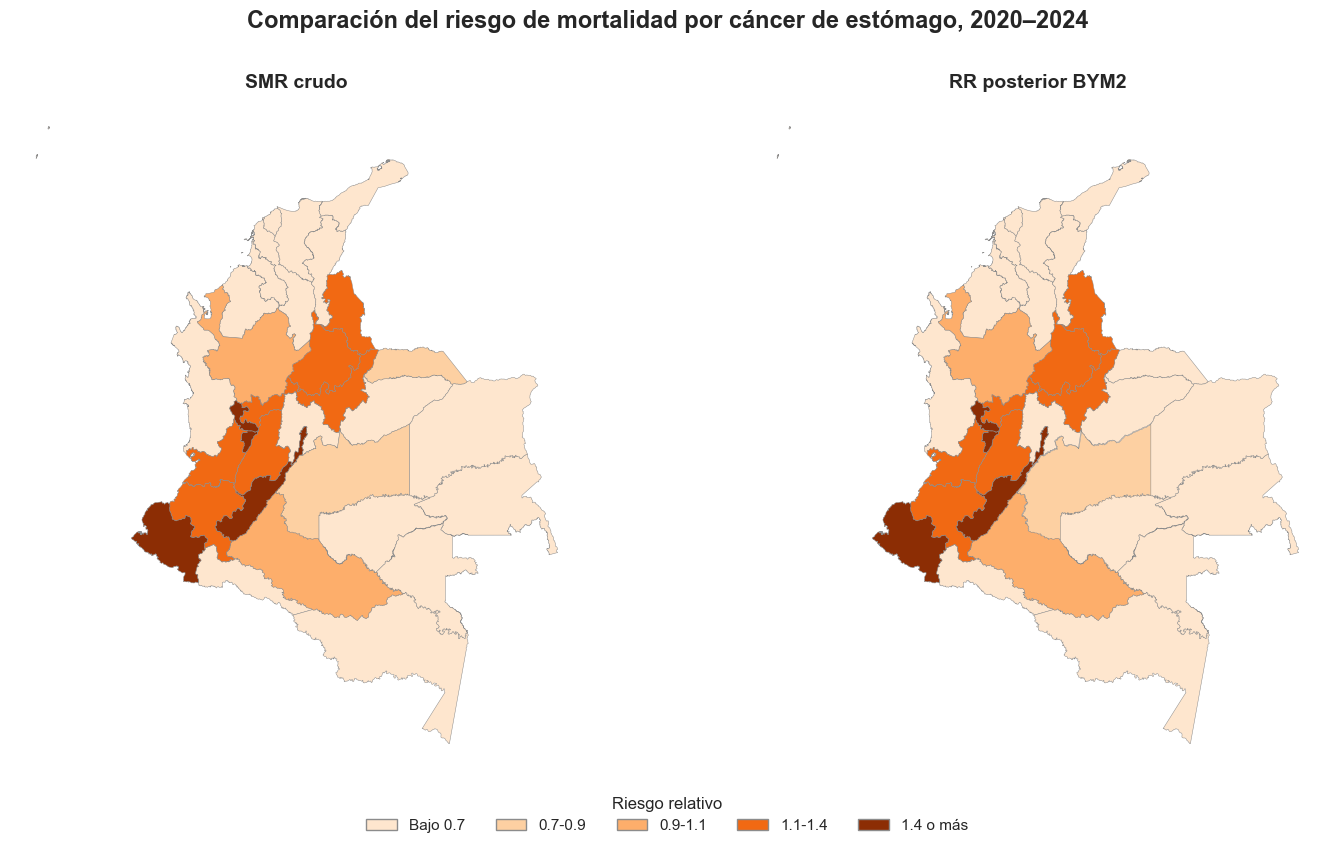

In [82]:
mapa_smr_2020_2024 = gdf_smr_quinquenal[
    gdf_smr_quinquenal["Quinquenio"] == "2020-2024"
].copy()

gdf_rr_2020_2024 = gdf_departamentos.merge(
    resultados_rr[
        ["dpto_ccdgo", "RR_media"]
    ],
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left"
)

gdf_rr_2020_2024["Categoria_RR"] = pd.cut(
    gdf_rr_2020_2024["RR_media"],
    bins=[-np.inf, 0.7, 0.9, 1.1, 1.4, np.inf],
    labels=[
        "RR < 0.7",
        "0.7 ≤ RR < 0.9",
        "0.9 ≤ RR < 1.1",
        "1.1 ≤ RR < 1.4",
        "RR ≥ 1.4"
    ],
    right=False
)

colores_comparacion = {
    "Bajo 0.7": "#fee6ce",
    "0.7-0.9": "#fdd0a2",
    "0.9-1.1": "#fdae6b",
    "1.1-1.4": "#f16913",
    "1.4 o más": "#8c2d04"
}

mapa_smr_2020_2024["Categoria_comparacion"] = pd.cut(
    mapa_smr_2020_2024["SMR"],
    bins=[-np.inf, 0.7, 0.9, 1.1, 1.4, np.inf],
    labels=list(colores_comparacion.keys()),
    right=False
)

gdf_rr_2020_2024["Categoria_comparacion"] = pd.cut(
    gdf_rr_2020_2024["RR_media"],
    bins=[-np.inf, 0.7, 0.9, 1.1, 1.4, np.inf],
    labels=list(colores_comparacion.keys()),
    right=False
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 9)
)

for categoria, color in colores_comparacion.items():
    subset_smr = mapa_smr_2020_2024[
        mapa_smr_2020_2024["Categoria_comparacion"] == categoria
    ]

    if not subset_smr.empty:
        subset_smr.plot(
            ax=axes[0],
            color=color,
            edgecolor="#8c8c8c",
            linewidth=0.35,
            aspect=1
        )

    subset_rr = gdf_rr_2020_2024[
        gdf_rr_2020_2024["Categoria_comparacion"] == categoria
    ]

    if not subset_rr.empty:
        subset_rr.plot(
            ax=axes[1],
            color=color,
            edgecolor="#8c8c8c",
            linewidth=0.35,
            aspect=1
        )

axes[0].set_title(
    "SMR crudo",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_title(
    "RR posterior BYM2",
    fontsize=14,
    fontweight="bold"
)

for ax in axes:
    ax.axis("off")

leyenda = [
    Patch(
        facecolor=color,
        edgecolor="#8c8c8c",
        label=categoria
    )
    for categoria, color in colores_comparacion.items()
]

fig.legend(
    handles=leyenda,
    title="Riesgo relativo",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.03),
    ncol=5,
    frameon=False
)

fig.suptitle(
    "Comparación del riesgo de mortalidad por cáncer de estómago, 2020–2024",
    fontsize=17,
    fontweight="bold",
    y=0.96
)

plt.tight_layout(rect=[0, 0.09, 1, 0.93])
plt.show()

In [86]:
comparacion_smr_bym2 = (
    smr_departamento_quinquenal[
        smr_departamento_quinquenal["Quinquenio"] == "2020-2024"
    ][["dpto_ccdgo", "DPNOM", "SMR"]]
    .merge(
        resultados_rr[
            ["dpto_ccdgo", "RR_media"]
        ],
        on="dpto_ccdgo",
        how="inner"
    )
)

comparacion_smr_bym2["Diferencia"] = (
    comparacion_smr_bym2["RR_media"]
    - comparacion_smr_bym2["SMR"]
)

comparacion_smr_bym2["Cambio_absoluto"] = (
    comparacion_smr_bym2["Diferencia"].abs()
)

comparacion_smr_bym2 = (
    comparacion_smr_bym2
    .sort_values("Cambio_absoluto", ascending=False)
    .reset_index(drop=True)
)

styled_comparacion = (
    comparacion_smr_bym2
    .style
    .hide(axis="index")
    .format({
        "SMR": "{:.3f}",
        "RR_media": "{:.3f}",
        "Diferencia": "{:+.3f}",
        "Cambio_absoluto": "{:.3f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["DPNOM"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_comparacion.to_html()
        + "</div>"
    )
)

dpto_ccdgo,DPNOM,SMR,RR_media,Diferencia,Cambio_absoluto
97,Vaupés,0.045,0.126,+0.080,0.080
94,Guainía,0.000,0.068,+0.068,0.068
99,Vichada,0.104,0.143,+0.039,0.039
95,Guaviare,0.488,0.455,-0.033,0.033
91,Amazonas,0.167,0.198,+0.031,0.031
88,"Archipiélago de San Andrés, Providencia y Santa Catalina",0.187,0.207,+0.021,0.021
18,Caquetá,1.092,1.079,-0.012,0.012
27,Chocó,0.150,0.161,+0.011,0.011
81,Arauca,0.704,0.699,-0.005,0.005
66,Risaralda,1.898,1.894,-0.004,0.004


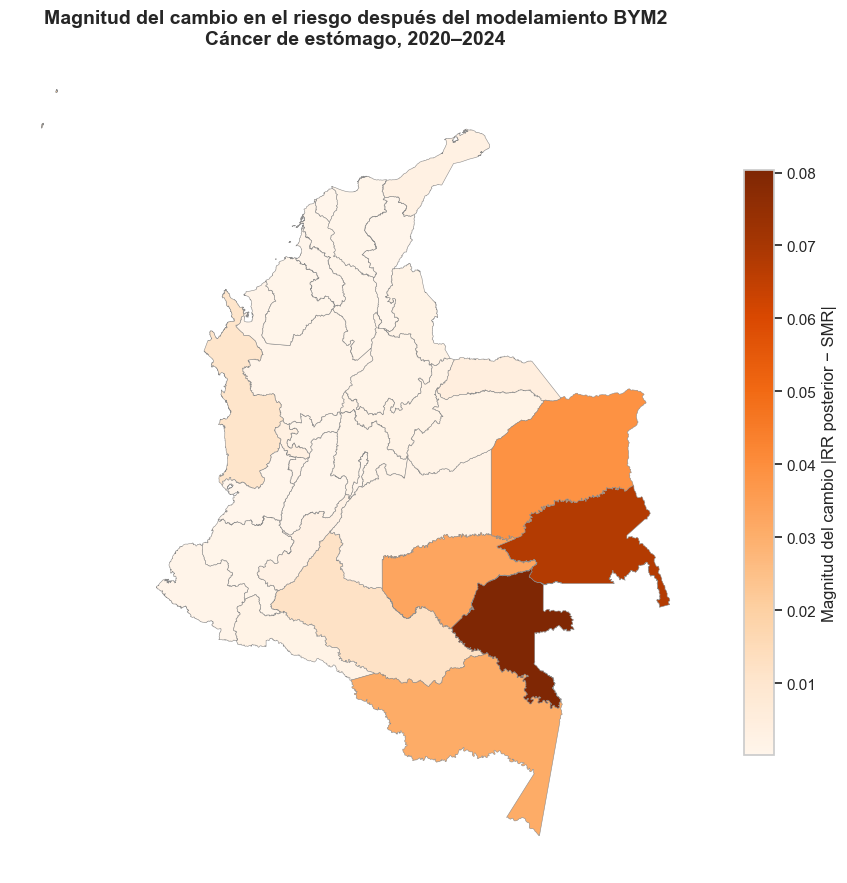

In [85]:
comparacion_mapa = gdf_departamentos.merge(
    comparacion_smr_bym2[
        ["dpto_ccdgo", "DPNOM", "SMR", "RR_media", "Diferencia"]
    ],
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left"
)

comparacion_mapa["Cambio_absoluto"] = comparacion_mapa["Diferencia"].abs()

fig, ax = plt.subplots(
    1,
    1,
    figsize=(9, 9)
)

comparacion_mapa.plot(
    column="Cambio_absoluto",
    cmap="Oranges",
    edgecolor="#8c8c8c",
    linewidth=0.4,
    legend=True,
    legend_kwds={
        "label": "Magnitud del cambio |RR posterior − SMR|",
        "shrink": 0.7
    },
    ax=ax
)

ax.set_title(
    "Magnitud del cambio en el riesgo después del modelamiento BYM2\nCáncer de estómago, 2020–2024",
    fontsize=14,
    fontweight="bold"
)

ax.axis("off")

plt.tight_layout()
plt.show()

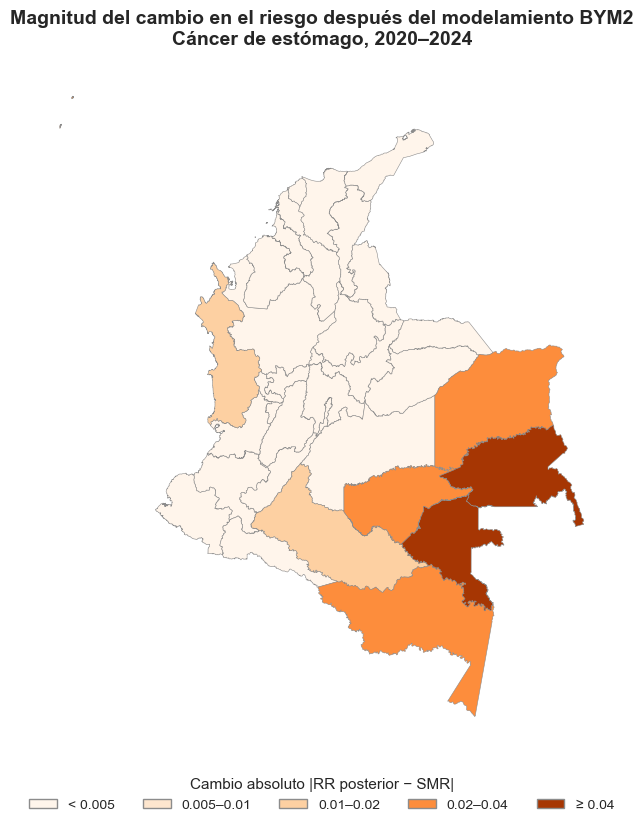

In [87]:
comparacion_mapa = gdf_departamentos.merge(
    comparacion_smr_bym2[
        ["dpto_ccdgo", "DPNOM", "SMR", "RR_media", "Diferencia"]
    ],
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left"
)

comparacion_mapa["Cambio_absoluto"] = comparacion_mapa["Diferencia"].abs()

comparacion_mapa["Categoria_cambio"] = pd.cut(
    comparacion_mapa["Cambio_absoluto"],
    bins=[-np.inf, 0.005, 0.01, 0.02, 0.04, np.inf],
    labels=[
        "< 0.005",
        "0.005–0.01",
        "0.01–0.02",
        "0.02–0.04",
        "≥ 0.04"
    ],
    right=False
)

colores_cambio = {
    "< 0.005": "#fff5eb",
    "0.005–0.01": "#fee6ce",
    "0.01–0.02": "#fdd0a2",
    "0.02–0.04": "#fd8d3c",
    "≥ 0.04": "#a63603"
}

orden_cambio = [
    "< 0.005",
    "0.005–0.01",
    "0.01–0.02",
    "0.02–0.04",
    "≥ 0.04"
]

fig, ax = plt.subplots(
    1,
    1,
    figsize=(9, 9)
)

for categoria, color in colores_cambio.items():
    subset = comparacion_mapa[
        comparacion_mapa["Categoria_cambio"] == categoria
    ]

    if not subset.empty:
        subset.plot(
            ax=ax,
            color=color,
            edgecolor="#8c8c8c",
            linewidth=0.4,
            aspect=1
        )

leyenda = [
    Patch(
        facecolor=colores_cambio[categoria],
        edgecolor="#8c8c8c",
        label=categoria
    )
    for categoria in orden_cambio
]

fig.legend(
    handles=leyenda,
    title="Cambio absoluto |RR posterior − SMR|",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.035),
    ncol=5,
    frameon=False,
    fontsize=10,
    title_fontsize=11
)

ax.set_title(
    "Magnitud del cambio en el riesgo después del modelamiento BYM2\nCáncer de estómago, 2020–2024",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.axis("off")

plt.tight_layout(rect=[0, 0.10, 1, 0.96])
plt.show()

### 7.3 Modelo Nulo

In [88]:
datos_modelo_nulo = {
    "N": datos_modelo["N"],
    "Y": datos_modelo["Y"],
    "E": datos_modelo["E"]
}

print("N:", datos_modelo_nulo["N"])
print("Observadas:", sum(datos_modelo_nulo["Y"]))
print("Esperadas:", round(sum(datos_modelo_nulo["E"]), 6))

N: 33
Observadas: 26418
Esperadas: 26418.0


In [96]:
modelo_bym2_loo = CmdStanModel(
    stan_file=r"C:\Users\USER\Desktop\Tesis\src\bym2_estomago_loo.stan"
)

21:32:31 - cmdstanpy - INFO - compiling stan file C:\Users\USER\Desktop\Tesis\src\bym2_estomago_loo.stan to exe file C:\Users\USER\Desktop\Tesis\src\bym2_estomago_loo.exe
21:32:48 - cmdstanpy - INFO - compiled model executable: C:\Users\USER\Desktop\Tesis\src\bym2_estomago_loo.exe


In [97]:
ajuste_bym2_loo = modelo_bym2_loo.sample(
    data=datos_modelo,
    chains=4,
    parallel_chains=4,
    iter_warmup=1000,
    iter_sampling=1000,
    seed=1234,
    adapt_delta=0.99,
    max_treedepth=15,
    show_progress=True
)

21:32:49 - cmdstanpy - INFO - CmdStan start processing


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

21:33:07 - cmdstanpy - INFO - CmdStan done processing.


In [98]:
print(ajuste_bym2_loo.stan_variables().keys())

resumen_bym2_loo = ajuste_bym2_loo.summary()

resumen_bym2_loo.loc[
    ["alpha", "sigma", "rho"],
    ["Mean", "50%", "StdDev", "N_Eff", "R_hat"]
].rename(
    columns={
        "50%": "Median",
        "N_Eff": "ESS"
    }
)

dict_keys(['alpha', 'sigma', 'rho', 'phi_conn', 'phi_island', 'delta', 'phi', 'efecto_espacial', 'log_rr', 'rr', 'log_lik'])


,Mean,Median,StdDev,ESS,R_hat
alpha,-0.52,-0.51,0.06,"4,295.75",1.00
sigma,0.86,0.85,0.13,"1,251.70",1.00
rho,0.92,0.96,0.11,439.26,1.01


In [102]:
log_lik_nulo = ajuste_nulo.stan_variable("log_lik")
log_lik_bym2 = ajuste_bym2_loo.stan_variable("log_lik")

print("Nulo:", log_lik_nulo.shape)
print("BYM2:", log_lik_bym2.shape)

print("\nValores finitos:")
print("Nulo:", np.isfinite(log_lik_nulo).all())
print("BYM2:", np.isfinite(log_lik_bym2).all())

Nulo: (4000, 33)
BYM2: (4000, 33)

Valores finitos:
Nulo: True
BYM2: True


In [103]:
from scipy.special import logsumexp

def calcular_waic(log_lik):
    n_draws = log_lik.shape[0]

    lppd_i = logsumexp(log_lik, axis=0) - np.log(n_draws)
    p_waic_i = np.var(log_lik, axis=0, ddof=1)

    elpd_waic_i = lppd_i - p_waic_i

    elpd_waic = np.sum(elpd_waic_i)
    p_waic = np.sum(p_waic_i)
    waic = -2 * elpd_waic

    return {
        "WAIC": waic,
        "ELPD_WAIC": elpd_waic,
        "p_WAIC": p_waic,
        "ELPD_i": elpd_waic_i
    }

waic_nulo = calcular_waic(log_lik_nulo)
waic_bym2 = calcular_waic(log_lik_bym2)

diferencia_elpd_i = (
    waic_bym2["ELPD_i"]
    - waic_nulo["ELPD_i"]
)

diferencia_elpd = np.sum(diferencia_elpd_i)
se_diferencia = np.sqrt(
    len(diferencia_elpd_i)
    * np.var(diferencia_elpd_i, ddof=1)
)

comparacion_waic = pd.DataFrame({
    "Modelo": ["Nulo", "BYM2"],
    "WAIC": [
        waic_nulo["WAIC"],
        waic_bym2["WAIC"]
    ],
    "ELPD_WAIC": [
        waic_nulo["ELPD_WAIC"],
        waic_bym2["ELPD_WAIC"]
    ],
    "p_WAIC": [
        waic_nulo["p_WAIC"],
        waic_bym2["p_WAIC"]
    ]
})

comparacion_waic["ΔWAIC vs mejor"] = (
    comparacion_waic["WAIC"]
    - comparacion_waic["WAIC"].min()
)

styled_waic = (
    comparacion_waic
    .style
    .hide(axis="index")
    .format({
        "WAIC": "{:.2f}",
        "ELPD_WAIC": "{:.2f}",
        "p_WAIC": "{:.2f}",
        "ΔWAIC vs mejor": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Modelo"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_waic.to_html()
        + "</div>"
    )
)

print(f"Diferencia ELPD (BYM2 - Nulo): {diferencia_elpd:.2f}")
print(f"Error estándar de la diferencia: {se_diferencia:.2f}")

Modelo,WAIC,ELPD_WAIC,p_WAIC,ΔWAIC vs mejor
Nulo,6057.50,-3028.75,237.53,5758.47
BYM2,299.03,-149.51,17.93,0.00


Diferencia ELPD (BYM2 - Nulo): 2879.24
Error estándar de la diferencia: 596.30


In [104]:
p_waic_i_nulo = np.var(log_lik_nulo, axis=0, ddof=1)
p_waic_i_bym2 = np.var(log_lik_bym2, axis=0, ddof=1)

diagnostico_waic = datos_bym2_ordenados[
    ["dpto_ccdgo", "DPNOM"]
].copy()

diagnostico_waic["p_WAIC_i_Nulo"] = p_waic_i_nulo
diagnostico_waic["p_WAIC_i_BYM2"] = p_waic_i_bym2
diagnostico_waic["Alerta_Nulo"] = diagnostico_waic["p_WAIC_i_Nulo"] > 0.4
diagnostico_waic["Alerta_BYM2"] = diagnostico_waic["p_WAIC_i_BYM2"] > 0.4

diagnostico_waic = (
    diagnostico_waic
    .sort_values("p_WAIC_i_BYM2", ascending=False)
    .reset_index(drop=True)
)

styled_diagnostico = (
    diagnostico_waic
    .style
    .hide(axis="index")
    .format({
        "p_WAIC_i_Nulo": "{:.3f}",
        "p_WAIC_i_BYM2": "{:.3f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["DPNOM"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_diagnostico.to_html()
        + "</div>"
    )
)

dpto_ccdgo,DPNOM,p_WAIC_i_Nulo,p_WAIC_i_BYM2,Alerta_Nulo,Alerta_BYM2
94,Guainía,0.029,1.194,False,True
97,Vaupés,0.016,0.828,False,True
99,Vichada,0.135,0.814,False,True
27,Chocó,2.279,0.596,True,True
95,Guaviare,0.018,0.587,False,True
86,Putumayo,0.140,0.570,False,True
85,Casanare,0.261,0.564,False,True
66,Risaralda,7.564,0.556,True,True
25,Cundinamarca,16.189,0.528,True,True
68,Santander,1.464,0.522,True,True


In [105]:
resumen_diagnostico_waic = pd.DataFrame({
    "Modelo": ["Nulo", "BYM2"],
    "Departamentos con p_WAIC_i > 0.4": [
        (p_waic_i_nulo > 0.4).sum(),
        (p_waic_i_bym2 > 0.4).sum()
    ],
    "Máximo p_WAIC_i": [
        p_waic_i_nulo.max(),
        p_waic_i_bym2.max()
    ],
    "p_WAIC total": [
        p_waic_i_nulo.sum(),
        p_waic_i_bym2.sum()
    ]
})

styled_resumen = (
    resumen_diagnostico_waic
    .style
    .hide(axis="index")
    .format({
        "Máximo p_WAIC_i": "{:.3f}",
        "p_WAIC total": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Modelo"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_resumen.to_html()
        + "</div>"
    )
)

Modelo,Departamentos con p_WAIC_i > 0.4,Máximo p_WAIC_i,p_WAIC total
Nulo,22,111.234,237.53
BYM2,33,1.194,17.93


La comparación mediante WAIC muestra una reducción sustancial del criterio de información para el modelo BYM2 respecto al modelo nulo. Sin embargo, el análisis de las contribuciones individuales a \(p_{\mathrm{WAIC}}\) evidencia valores elevados en algunas unidades, particularmente en departamentos con menor información. Por esta razón, la comparación se utiliza como evidencia complementaria del mejor ajuste del modelo espacial y no como único criterio para establecer su desempeño predictivo.